In [1]:
#| echo: false

import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import arviz as az
import pyarrow
import xarray as xr

random_seed = 42

In [2]:
#| echo: false

import matplotlib.patheffects as pe
from matplotlib import font_manager as fm
from cycler import cycler

%config InlineBackend.figure_format = "retina"   # uncomment in a notebook

# NCM Regular and Book register under the same family name and weight,
# so matplotlib picks between them arbitrarily -- drop Book so Regular
# (the same cut the site's headers use) always wins.
fm.fontManager.ttflist = [f for f in fm.fontManager.ttflist
                        if not f.fname.split("/")[-1].startswith("NewCM10-Book")]

plt.rcParams.update({
    # Font -- New Computer Modern for everything
    "font.family": "serif",
    "font.serif": ["NewComputerModern", "CMU Serif", "cmr10"],
    "mathtext.fontset": "cm",              # math ($...$) renders in matching Computer Modern
    "axes.formatter.use_mathtext": True,   # axis-offset text (e.g. 1e6) also respects it
    "axes.unicode_minus": True,            # NCM has a proper minus glyph (cmr10 didn't)
    "axes.titleweight": 400,               # Regular + stroke, like the site's headers (NCM's 700 is a true heavy bold)
    "axes.labelweight": 400,
    "axes.titlesize": 20,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.titlepad": 16,

    # Hairline glyph outline matching the site's -webkit-text-stroke: 0.6px
    # (0.6 CSS px at 100 dpi = 0.43pt). No foreground given, so the stroke
    # takes each text's own color.
    "path.effects": [pe.Stroke(linewidth=0.43), pe.Normal()],

    # Colors -- matched to the site's --color-text / --color-muted tokens
    "text.color": "#1D1D1F",
    "axes.labelcolor": "#1D1D1F",
    "xtick.color": "#6B6A67",
    "ytick.color": "#6B6A67",
    "axes.edgecolor": "#D6D4CE",
    "grid.color": "#D6D4CE",
    "grid.alpha": 0.6,
    # Color cycle -- vivid, with the site's exact accent orange in slot 2.
    # Blue-then-orange order mirrors matplotlib's default, so existing
    # two-series plots keep the same color mapping.
    "axes.prop_cycle": cycler(color=[
        "#2563C9",  # blue
        "#E07335",  # orange -- site --color-accent
        "#12977F",  # teal
        "#7B48C9",  # purple
        "#C93A55",  # crimson
        "#D9A21B",  # gold
    ]),
    "lines.linewidth": 2,
    "legend.facecolor": "#F2F0EC",   # legend box blends into the background instead of white
    "legend.edgecolor": "#D6D4CE",

    # Spines
    "axes.spines.top": True,
    "axes.spines.right": True,

    # Ticks
    "xtick.bottom": False,
    "ytick.left": False,

    # Background -- matched to the site's --color-bg (light mode only;
    # static exported plot images can't follow the reader's dark-mode
    # toggle the way the CSS does, so this targets the light palette)
    "figure.facecolor": "#F2F0EC",
    "axes.facecolor": "#F2F0EC",
    "savefig.facecolor": "#F2F0EC",

    # Layout
    "figure.dpi": 100,
    "axes.xmargin": 0.02,
    "axes.ymargin": 0.05,

    # Prevents subplot titles/labels from overlapping the axes above
    # them in multi-row figures (e.g. az.plot_trace's per-parameter
    # grid) -- matplotlib resolves spacing automatically at draw time
    # rather than using fixed margins.
    "figure.constrained_layout.use": True,
})

In [3]:
#| echo: false
#| output: false

# Dataframe summary helper function. All distances are returned in inches;
# d' is a ratio of distances, so it's unit-free and unaffected.

def build_summary(
        trace,
        df,
        id_col: str,
        name_col: str,
        noise_mean: float,
        signal_mean: float,
        var_names: list[str] = ['c', 'sigma'],
        hdi_prob: float = 0.95,
) -> pd.DataFrame:

    var_names = list(var_names)
    name_map = dict(zip(df[id_col].astype('str'), df[name_col]))
    
    post = trace['posterior'].dataset
    delta = (signal_mean - noise_mean) / 12  # convert to feet for the model's scale

    # d' per posterior draw: a fixed separation over each draw of sigma
    d_prime_draws = xr.Dataset({'d_prime': delta / post['sigma']})

    dp_mean = (d_prime_draws['d_prime']
               .mean(dim=('chain', 'draw'))
               .to_dataframe(name='d_prime_mean')[['d_prime_mean']])

    dp_hdi = az.hdi(d_prime_draws, prob=hdi_prob)
    dp_hdi = getattr(dp_hdi, 'dataset', dp_hdi)   # DataTree or Dataset, depending on input
    dp_lb = dp_hdi['d_prime'].sel(ci_bound='lower').to_dataframe(name='d_prime_ci_lb')[['d_prime_ci_lb']]
    dp_ub = dp_hdi['d_prime'].sel(ci_bound='upper').to_dataframe(name='d_prime_ci_ub')[['d_prime_ci_ub']]

    means_df = (
        trace['posterior'].dataset[var_names]
        .mean(dim=('chain','draw'))
        .to_dataframe()
        .add_suffix('_mean')
    )

    hdi_ds = az.hdi(trace, var_names=var_names, prob=hdi_prob)
    hdi_dataset = hdi_ds.dataset
    lb_df = hdi_dataset.sel(ci_bound='lower').to_dataframe().add_suffix('_ci_lb')
    ub_df = hdi_dataset.sel(ci_bound='upper').to_dataframe().add_suffix('_ci_ub')
    
    summary = pd.concat([means_df, lb_df, ub_df], axis=1)

    ordered_cols = [
        f"{var}{suffix}"
        for var in var_names
        for suffix in ["_mean", "_ci_lb", "_ci_ub"]
    ]

    summary = summary[ordered_cols]
    summary = pd.concat([summary, dp_mean, dp_lb, dp_ub], axis=1)

    summary = (summary
            .assign(player_name=lambda x: x.index.map(name_map)
            )
            )


    summary = summary[['player_name','c_mean','c_ci_lb','c_ci_ub','sigma_mean','sigma_ci_lb','sigma_ci_ub','d_prime_mean','d_prime_ci_lb','d_prime_ci_ub']]

    # feet -> inches. c and sigma are on a linear scale here, so scaling
    # the posterior means and HDI bounds is exact.
    inch_cols = ['c_mean','c_ci_lb','c_ci_ub','sigma_mean','sigma_ci_lb','sigma_ci_ub']
    summary[inch_cols] = summary[inch_cols] * 12

    return summary

In [4]:
#| echo: false

def convert_to_in(posterior, noise_mean, signal_mean):

    delta_ft = (signal_mean - noise_mean) / 12

    log_sd = posterior['tau_logsig']
    sigma_mean = 12 * np.exp(posterior['mu_logsig'] + log_sd**2 / 2)
    sigma_sd = 12 * np.exp(posterior['mu_logsig'] + log_sd**2 / 2) * np.sqrt(np.expm1(log_sd**2))

    data = xr.Dataset({
        'c_mean': posterior['mu_c'] * 12,                 # typical criterion (in)
        'c_sd': posterior['tau_c'] * 12,                # SD of c across players (in)
        'sigma_mean': sigma_mean,                    # mean sigma (in)
        'sigma_sd': sigma_sd,                          # SD of sigma across players (in)
        })

    d_prime_mean = delta_ft * np.exp(-posterior['mu_logsig'] + log_sd**2 / 2)
    d_prime_sd   = d_prime_mean * np.sqrt(np.expm1(log_sd**2))

    data = data.assign(
        d_prime_mean=d_prime_mean,   # mean d' across players
        d_prime_sd=d_prime_sd,       # SD of d' across players
    )

    return data, delta_ft

In [5]:
#| echo: false

# Function to generate classic SDT plots for a given player.
# Expects a summary from build_summary(), with distances in inches.

def plot_sdt(
        player_id: str,
        summary_df,
        noise_mean: float,
        signal_mean: float,
        x_min: float = -20,
        x_max: float = 20,
        y_max: float | None = None,
):
        plot_id = player_id
        row = summary_df.loc[player_id]

        x = np.linspace(x_min, x_max, 1000)

        fig, ax = plt.subplots(figsize=(8, 6))
        plt.plot(x, stats.norm.pdf(x, noise_mean, row['sigma_mean']), label='Noise (Correct Calls)')
        plt.fill_between(x, stats.norm.pdf(x, noise_mean, row['sigma_mean']), alpha=0.2)
        plt.plot(x, stats.norm.pdf(x, signal_mean, row['sigma_mean']), label='Signal (Missed Calls)')
        plt.fill_between(x, stats.norm.pdf(x, signal_mean, row['sigma_mean']), alpha=0.2)
        plt.axvline(row['c_mean'], color='#7B48C9', linestyle='--', label=f'Criterion $c = {row['c_mean']:.2f}$"')
        plt.axvspan(row['c_ci_lb'],row['c_ci_ub'], alpha=0.1, color='#7B48C9')
        plt.xlim(x_min, x_max)
        plt.xlabel('Judged distance from zone edge (in)')
        plt.ylabel('Density')
        plt.title(f'{row['player_name']}')
        plt.legend()

        # y-height where the bracket sits (above the curve peaks). Offsets are
        # proportional to the peak so they scale with the units of x.
        y_peak = stats.norm.pdf(noise_mean, noise_mean, row['sigma_mean'])
        y_bracket = y_peak * 1.04
        tick = y_peak * 0.02

        x_left = noise_mean    # left mean (noise peak)
        x_right = signal_mean    # right mean (signal peak)

        # horizontal span
        ax.plot([x_left, x_right], [y_bracket, y_bracket], color='black', lw=1.2)
        # end ticks pointing down
        ax.plot([x_left, x_left], [y_bracket, y_bracket - tick], color='black', lw=1.2)
        ax.plot([x_right, x_right], [y_bracket, y_bracket - tick], color='black', lw=1.2)

        # label centered above
        ax.text((x_left + x_right) / 2, y_bracket + y_peak * 0.015, f"$d'$ = {row['d_prime_mean']:.2f}",
                ha='center', va='bottom', fontsize=13)

        # Fixed y_max keeps plots within a group comparable; otherwise leave headroom for the d' label
        ax.set_ylim(0, y_max if y_max is not None else y_peak * 1.18)


        plt.show()

[View the Jupyter Notebook](https://github.com/chrishires/abs-sdt/blob/main/part1.ipynb)  
[Visit the GitHub Repo](https://github.com/chrishires/abs-sdt)

![](images/abs2.png)

## Introduction

For years, there was an official rule in Major League Baseball that prohibited arguing with the umpire about whether a pitch was a ball or a strike. If a player, manager or coach left their position to argue a call, they could be expelled from the game. But for the 2026 season, Major League Baseball said, "ok, actually, you can argue them a little bit," and instituted a new challenge system that uses Automated Ball-Strike (ABS) technology. 

Baseball fans tend to be a pretty traditional bunch, so this caused some handwringing at the beginning of the year. However, after a full season, fans have mostly accepted the new system and in many cases embraced it. I, for one, [welcome our new robot overlords](https://www.youtube.com/watch?v=8lcUHQYhPTE).

For those who are unfamiliar with ABS, the basics are:

1. Each team starts the game with two available ABS challenges. If they challenge correctly, they retain that challenge, otherwise they lose it.[^extras]
2. Only the batter, pitcher or catcher can challenge the umpire's call. Managers, position players, or other personnel are not allowed to challenge.
3. Players initiate the challenge by tapping their cap or helmet. The challenge must be made immediately and without assistance from the bench or other players.[^assistance]
4. After a few seconds, the broadcast and the stadium video board show a graphic animation of the ball's location as it crossed the plate. Everyone learns the outcome at the same time, which makes for some [fantastic entertainment](https://x.com/CBoxSports/status/2038019886987804681).

It did not take long for the baseball analytics community to start coming up with ways to measure ABS challenges.[^savant] Many ABS analyses measure a player's success by the percentage of correct challenges they've recorded (precision). Others go further by estimating the challenges a player left on the table (recall). The problem with this approach is it confounds two aspects of the challenge decision into one number.

Challenging a call is a *judgement* based on a physical stimulus. The judgement has two parts: perception and a decision. If two players have different success rates on challenges, is this because they see the strike zone differently, have different risk preferences, or both? [Signal Detection Theory](https://en.wikipedia.org/wiki/Detection_theory) (SDT) answers these questions with a single model.

[^savant]: MLB's Baseball Savant site has [a particularly good dashboard](https://baseballsavant.mlb.com/leaderboard/abs-challenges).

[^extras]: In extra innings, any team that begins the inning with zero challenges will get one (1) extra challenge. If they exhaust that challenge, they get another one in the next extra inning. The ceiling is two (if you didn't use them during the first nine innings), and the floor is one.

[^assistance]: The definition of "assistance" is something of a subjective grey area. Controversially, some umps have denied some challenges by claiming the player [took too long](https://www.mlb.com/news/joc-pederson-ejected-from-game-vs-white-sox) or [received assistance](https://x.com/FoulTerritoryTV/status/2082323093972783251) from the bench.


## Signal Detection Theory

SDT lives at the intersection of [psychophysics](https://en.wikipedia.org/wiki/Psychophysics) and [decision theory](https://en.wikipedia.org/wiki/Decision_theory), studying humans' ability to differentiate between information (signal) and random activity, which is devoid of information (noise). You can apply SDT to virtually any yes/no task, and it's the kind of thing you start to recognize everywhere once you're aware of it. [Hiring decisions](https://rssclab.ucr.edu/wp-content/uploads/2026/07/Jakobetal2026.pdf), [dating](https://scholarlypublications.universiteitleiden.nl/handle/1887/4308691),[^hinge] [identifying misinformation](https://ijoc.org/index.php/ijoc/article/view/25051), and [detecting AI content](https://aisel.aisnet.org/amcis2026/sig_hci/sig_hci/23/) are all modern applications of SDT.

In an SDT study, subjects make a yes/no choice based on a *decision variable*. For a baseball player, the decision variable is their perceived location[^perception] of the pitch relative to the strike zone. If the decision variable is sufficiently high, the subject will respond "yes" (they'll challenge), and will otherwise respond "no" (they won't challenge). 

How much is "sufficient?" That's defined by the *criterion*, represented by the variable, $c$, which tells us how wrong they *think* the call needs to be in order to challenge it. Players with a low criterion are more likely to challenge a borderline call, while players with a high criterion are likely to challenge only the most egregious calls. The criterion is different for every player, and it partially explains why two players may have different responses to the same call.

In SDT terms, an incorrectly called pitch is called a *signal trial*, while a correctly called pitch is a *noise trial*. Challenging a missed call is a *true positive*, and letting it go is a *false negative*. Challenging a correct call is a *false positive*, and letting it go is a *true negative*. On every taken pitch, a player perceives the ball at different distances inside or outside the strike zone, and makes a judgement call to challenge or not. In aggregate, this forms two random distributions: one for signal pitches (missed calls), and one for noise pitches (correct calls). These distributions can be plotted and compared, like so:

[^hinge]: I couldn't find examples involving dating apps specifically, which seems like a ripe area for research. If you work at Hinge, call me.
[^perception]: This will almost always be different from the actual location of the pitch!

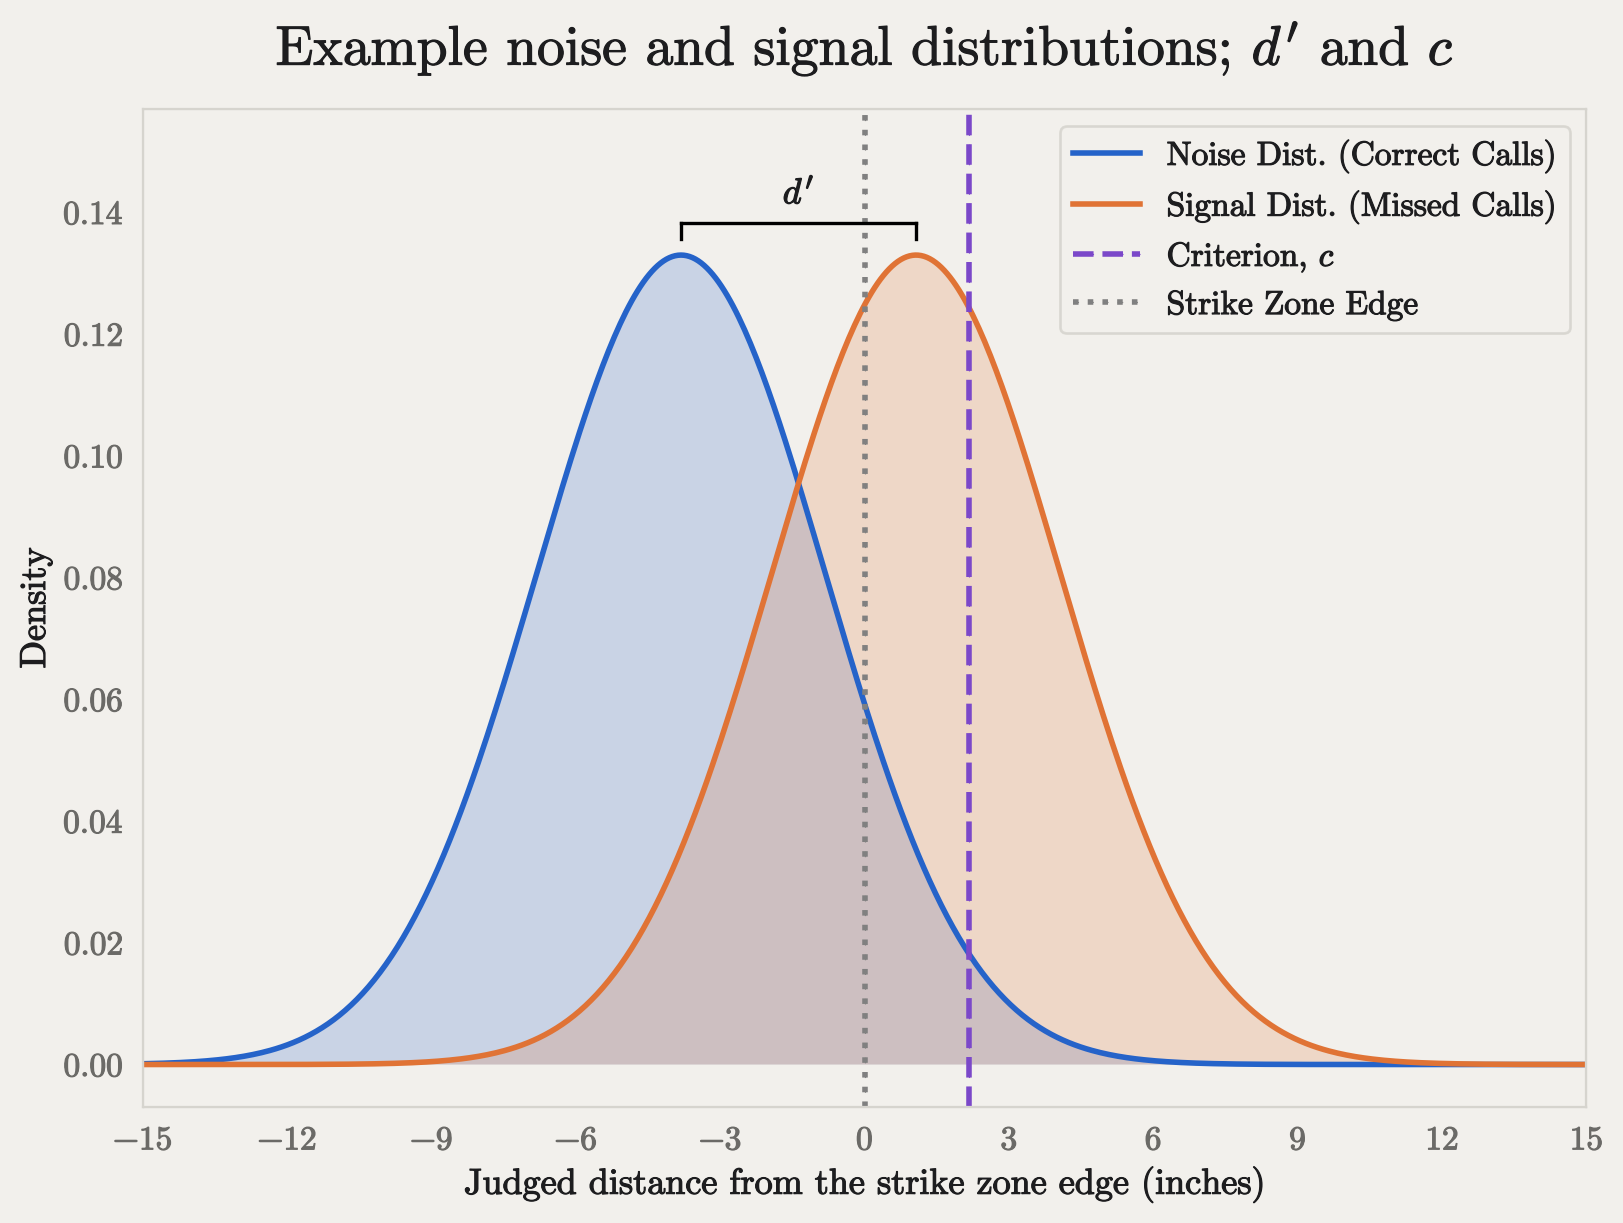

In [6]:
#| echo: false
#| label: fig-example
#| fig-cap: "Example signal and noise distributions for a hypothetical hitter. The bracket spans the distance between the two means, and the dashed line marks the criterion $c$."

# Example parameters, in inches
noise_mean = -0.318 * 12
sigma_mean = 0.25 * 12
signal_mean = 0.089 * 12
c_mean = 0.18 * 12
d_prime = 1.5

x = np.linspace(-15, 15, 500)

fig, ax = plt.subplots(figsize=(8, 6))
plt.plot(x, stats.norm.pdf(x, noise_mean, sigma_mean), label='Noise Dist. (Correct Calls)')
plt.fill_between(x, stats.norm.pdf(x, noise_mean, sigma_mean), alpha=0.2)
plt.plot(x, stats.norm.pdf(x, signal_mean, sigma_mean), label='Signal Dist. (Missed Calls)')
plt.fill_between(x, stats.norm.pdf(x, signal_mean, sigma_mean), alpha=0.2)
plt.axvline(c_mean, color='#7B48C9', linestyle='--', label=f'Criterion, $c$')
plt.axvline(0, color='gray', linestyle='dotted', label='Strike Zone Edge')
plt.xticks(np.arange(-15, 18, 3))
plt.xlim(-15, 15)
plt.xlabel('Judged distance from the strike zone edge (inches)')
plt.ylabel('Density')
plt.title("Example noise and signal distributions; $d'$ and $c$")
plt.legend(loc='upper right')

# y-height where the bracket sits (above the curve peaks). Offsets are
# proportional to the peak so they scale with the units of x.
y_peak = stats.norm.pdf(noise_mean, noise_mean, sigma_mean)
y_bracket = y_peak * 1.04
tick = y_peak * 0.02

x_left = noise_mean      # left mean (noise peak)
x_right = signal_mean    # right mean (signal peak)

# horizontal span
ax.plot([x_left, x_right], [y_bracket, y_bracket], color='black', lw=1.2)
# end ticks pointing down
ax.plot([x_left, x_left], [y_bracket, y_bracket - tick], color='black', lw=1.2)
ax.plot([x_right, x_right], [y_bracket, y_bracket - tick], color='black', lw=1.2)

# label centered above
ax.text((x_left + x_right) / 2, y_bracket + y_peak * 0.015, f"$d'$",
        ha='center', va='bottom', fontsize=13)

ax.set_ylim(top=y_peak * 1.18)   # headroom so the d' label clears the top edge

plt.show()

These curves are **not** the distributions of actual pitch locations. We infer them from the player's behavior, and they represent the way a player would *treat* a typical pitch in each category. The blue curve is the range of judged pitch locations for the typical correct call; the orange curve for a typical missed call. 

In the diagram, about 36% of the orange signal distribution is below zero. For a hitter, these pitches are outside the zone by definition, but their behavior treats them as though they're strikes. This might be because they see the pitch as a strike (just like the umpire), or it might be that they don't think the pitch is worth challenging. The same goes for the blue curve, where roughly 10% is outside the strike zone. This means, given their challenge history, there's a roughly 10% chance this player will treat a true strike *as though* it is outside the strike zone. That doesn't guarantee they'll challenge that pitch, though - that depends on their criterion, and another value called sigma ($\sigma$). 

The dashed purple line is the inferred value of the player's decision criterion. It represents the distance beyond the zone at which there's a 50% probability the player will challenge.[^absolute_c] The consistency of a player's behavior is governed by a single parameter: $\sigma$. A player with a small $\sigma$ is predictable: pitches beyond their criterion almost always get challenged, and pitches short of it almost never do. A player with a large $\sigma$ is erratic: they'll challenge some pitches that were actually strikes and let some obvious misses go.

The width of the curves is also governed by $\sigma$. The larger $\sigma$ gets, the more these curves overlap, and the less we'd expect a player to discriminate between correct calls and missed calls when challenging (that's bad, fyi). A subject with $\sigma$ near zero would have two sharp spikes that barely touch.

A player's ability to discriminate signal from noise is known as *sensitivity*. Sensitivity is measured as the difference between the means of the two distributions, measured in units of $\sigma$. This measurement is called $d'$ (pronounced "dee prime"). For $d'=0$, a player would have no ability to distinguish between a missed call and a correct one, and you'd see two completely overlapping curves.

To avoid sampling noise, each SDT plot in this analysis uses the averages for *all* correct calls and missed calls seen by hitters and catchers, rather than the pitches each player happened to see. The width of the curves ($\sigma$) and the location of the criterion line will vary from player to player based on model estimates. Each plot also shades the 95% credible interval around the criterion, which is wider for players with fewer challenge observations.

::: {.callout-note}
In a controlled SDT experiment, participants have to make a yes/no choice every time. But an ABS challenge is optional, and a player who sees a missed call perfectly well might decline to challenge it for any number of reasons. We can't know why they don't challenge, only that they don't. Controlled experiments make it easier to interpret $\sigma$ and $d'$ as measures of perception, but in this analysis, we are using them to measure behavior.

In Part 2, we'll take a closer look at the factors that may or may not cause a player to refrain from a challenge.
:::

[^absolute_c]: In traditional SDT, $c$ is measured as the distance between the midpoint of the distributions (roughly -1.4 inches in the figure) and the decision boundary. In this analysis, we'll measure $c$'s absolute location relative to the strike zone.

In [7]:
#| echo: false

data = pd.read_parquet('pitch_data.parquet')

## The Data

MLB's Stats API is an embarrassment of riches for sports analytics nerds. Every game comes with an event-by-event feed: every pitch, pickoff, substitution and replay review, each tagged with who was involved and what happened. For pitches and batted ball events, you also get kinematic data describing the velocity and acceleration of the ball in three dimensions. For our model, we need to know three things:

1. The true location of the pitch, as measured by the Hawk-Eye camera system in every MLB stadium.
2. Whether the pitch was called correctly or incorrectly by the umpire.
3. Whether a player challenged a pitch, and the outcome of that challenge.

This [ETL script](https://github.com/chrishires/abs-sdt/blob/main/ETL.ipynb) calls MLB's Stats API, retrieves the schedule, and loops through every pitch of every game, gathering these three data points, along with a lot of other data about the game that we'll discuss in Part 2.

Once the ETL has run, we have a table with 714,483 rows and 66 columns, where each row is a pitch. 

Occasionally, the API fails to record the kinematic data for a pitch. This data is critical for point number one above, but given our large full-season sample, dropping at-bats that contain these errors does not affect the quality of the sample. After dropping 110 affected at-bats (450 pitches), the table contains **714,033** pitches.

The universe of pitches we care about only includes *taken* pitches (those where the hitter did not swing), as all other pitch events are not challengeable via ABS. We also set aside pitches thrown after the player's team had used up its challenges, since there's no longer a challenge decision to be made.[^no-challenges] That leaves 106,721 called strikes a batter could have challenged, and 238,416 called balls a catcher could have challenged.

[^no-challenges]: This removes about 7% of the called pitches, and it matches how [Baseball Savant](https://baseballsavant.mlb.com/leaderboard/abs-challenges?challengeType=catcher&level=mlb&minChal=1&minOppChal=0&sort=n_challenges&sortDir=desc&page=0&pageSize=50&season%5B%5D=2026&gameType%5B%5D=R) counts challenge opportunities. Leaving those pitches in would count each one as a decision not to challenge, pushing every player's estimated criterion upward.

## Pitch Geometry

![The ABS zone is slightly different from the Statcast zone. Credit: [mlb.com](https://www.mlb.com/news/automated-ball-strike-calls-mlb-spring-games)](images/b4qmqymbxehalzri3ztp.png)



This analysis treats the ABS measurement as the ground truth,[^errors] but we only get to observe that truth when someone challenges a pitch. For our model, we also need to observe the truth when there was no challenge. This means our data needs to include the location of the pitch in the same place ABS would measure it. Unfortunately, this is not what's in the data! 

The Stats API reports a pitch's location as it crosses the **front** of the plate, but ABS judges its location at the **midpoint** of the plate, 8.5 inches deeper. This means we need to solve some quadratic equations (I'm sorry to inform you your high school teacher was right) to estimate the location of the ball in the ABS plane. Statcast gives us nine parameters - $x$, $y$ and $z$ for position, velocity and acceleration - at $y_0 = 50$ ft from the plate. The ball's depth along the pitch's path at time $t$ (measured in seconds) is:

$$y(t) = y_0 + v_{y0}\,t + \tfrac{1}{2}a_y t^2$$

Setting $y(t)$ equal to the plate's midpoint ($y_{mid} = 8.5\text{in}/12\text{in} = 0.708\text{ft}$) and solving the quadratic gives the time the ball crosses it:[^root]

$$t_{mid} = \frac{-v_{y0} - \sqrt{v_{y0}^2 - 2a_y\,(y_0 - y_{mid})}}{a_y}$$

Plugging that back in gives us the ball's location at the midpoint:

$$x_{mid} = x_0 + v_{x0}\,t_{mid} + \tfrac{1}{2}a_x t_{mid}^2, \qquad z_{mid} = z_0 + v_{z0}\,t_{mid} + \tfrac{1}{2}a_z t_{mid}^2$$

The estimate is pretty good: it matches ABS's actual ruling on **99.7%** of the season's 10,556 challenged pitches.

Two more details: ABS calls a strike if *any part* of the ball touches the zone. This means we need to pad the zone by the ball's radius (1.45 in) on every side, so "center of the ball inside the padded zone" means exactly "some of the ball touched the real zone." The zone is 17 inches wide for everyone, but its top and bottom are specific to each batter.[^short_kings]

Finally, each pitch gets a **signed distance** from the strike zone edge, calculated as the Euclidean distance to the nearest edge of the padded zone. For batters, positive means the pitch was outside by that much. For catchers, a positive value means the pitch was in the zone. In both cases, a positive value indicates a challengeable pitch, and $d = 0$ is the point where the whole ball has just cleared the zone.

To calculate, we let the padded strike zone be the rectangle
$[x_{\text{left}}, x_{\text{right}}] \times [z_{\text{bot}}, z_{\text{top}}]$,
where the rule-book zone is expanded by the ball's radius $r = 1.45$ in on
every side, and let $(p_x, p_z)$ be the pitch location at the plate midpoint.

The horizontal and vertical excursions outside the zone are:
$$
\Delta_x = \max\left(x_{\text{left}} - p_x,\; 0,\; p_x - x_{\text{right}}\right),
\qquad
\Delta_z = \max\left(z_{\text{bot}} - p_z,\; 0,\; p_z - z_{\text{top}}\right),
$$

each of which is zero whenever the pitch falls within the zone's span on that
axis. The signed distance to the nearest edge is then:

$$
d =
\begin{cases}
\sqrt{\Delta_x^2 + \Delta_z^2}
  & \text{if } \Delta_x > 0 \text{ or } \Delta_z > 0, \\[2ex]
-\min\left(p_x - x_{\text{left}},\;
           x_{\text{right}} - p_x,\;
           p_z - z_{\text{bot}},\;
           z_{\text{top}} - p_z\right)
  & \text{otherwise.}
\end{cases}
$$

Signed distance is a departure from traditional SDT, which treats the presence of the signal as binary. The underlying assumption is that a high signed distance value is a stronger signal than a low one. In other words, a ball just off the plate is much harder to detect than a ball that sails over a batter's head, and the model takes that into account.

[^errors]: [Some may take issue with this](https://www.nytimes.com/athletic/7142476/2026/03/24/mlb-abs-error-margin/) but I say it's close enough.

[^root]: $v_{y0}$ is negative because the ball is traveling toward the plate, and $a_y$ is positive because drag slows it down. The quadratic has two positive roots. The smaller one is the actual crossing; the other is where the fitted parabola would come back if the ball kept going.

[^short_kings]: MLB had to measure each player to obtain their strike zone measurements, with [hilarious consequences](https://www.nytimes.com/athletic/7155626/2026/03/30/mlb-short-kings-height-measurements-changing-abs/).

In [8]:
#| echo: false
#| output: false

# Only pitches where the batting team still had a challenge left (Savant's definition of an opportunity)
hitters =  data[(data['originalCall'] == 'Called Strike') & (data['pre_batting_challenges'] > 0)][['batter_id','batter','review_player_id','off_edge_dist','TP','FP','TN','Off_FN']]
hitters['challenge'] = np.where(hitters['review_player_id'] == hitters['batter_id'],1,0)

In [9]:
#| echo: false
# Data Prep

batter_ids = hitters['batter_id'].astype('category')
n_players = len(batter_ids.cat.categories)
n_pitches = len(hitters)
obs_ids = np.arange(n_pitches)
batter_idx = batter_ids.cat.codes.to_numpy().astype('int64')
distance = hitters['off_edge_dist'].to_numpy()
challenge = hitters['challenge'].to_numpy()

## The Model

### The Generative Story

A pitch crosses the plate at a true signed distance $d$ from the zone edge.[^confusion] The model borrows the standard SDT story: the player doesn't act on $d$ directly, but on a noisy internal version of it, the true distance plus some random error. We assume that error is normally distributed, with mean zero and variance $\sigma^2$:

$$X = d + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2)$$

$d$ is fixed for a given pitch, but $\varepsilon$ is redrawn on every trial, which is why the same pitch could produce different decisions from the same player on two occasions. In a laboratory task, $\varepsilon$ would be pure perceptual error. Here, as discussed above, it absorbs anything that makes a player's decision vary for a given pitch: an imprecise read, a threshold that shifts with the situation, a reluctance to challenge at all. The $\sigma$ that sets its spread is the same quantity that governs the overlap of the signal and noise distributions.

The player challenges when $X$ exceeds their idiosyncratic criterion:

$$X > c$$

We never observe $X$, only whether the player challenged. So we ask: for a pitch at true distance $d$, what is the probability of a challenge?

$$P(\text{challenge} \mid d) = P(d + \varepsilon > c) = P(\varepsilon > c - d)$$

Because $\varepsilon$ is Gaussian, this is a tail probability of a normal distribution, which the normal CDF answers directly. For a $\mathcal{N}(0, \sigma^2)$ variable, $P(\varepsilon \le t) = \Phi(t/\sigma)$, where $\Phi$ is the standard normal CDF and dividing by $\sigma$ standardizes. Taking the complement:

$$P(\text{challenge} \mid d) = 1 - \Phi\!\left(\frac{c - d}{\sigma}\right)$$

And because the standard normal is symmetric around zero, $1 - \Phi(u) = \Phi(-u)$. Flipping the sign of the argument gives:

$$P(\text{challenge} \mid d) = \Phi\!\left(\frac{d - c}{\sigma}\right)$$

This is a [probit regression](https://en.wikipedia.org/wiki/Probit_model), a close cousin of logistic regression. Both turn a linear predictor into a probability; logistic regression uses the logistic curve, while probit uses the standard normal CDF, $\Phi$, to take a z-score and return a probability.[^probit] We're already standardizing $d - c$ by dividing by $\sigma$, so $\Phi$ turns it directly into a probability of challenging. The choice of $\Phi$ isn't arbitrary: it follows from assuming the error is normally distributed. When $d$ is well above $c$, the probability approaches 1; well below, it approaches 0; and at $d = c$ it is exactly 0.5, which is what the criterion means: the distance at which a player challenges half the time.

### The Hierarchy

The model is hierarchical: each player's $c$ and $\sigma$ are themselves drawn from population distributions. $c_i$ is normal, governed by a population mean $\mu_c$ and standard deviation $\tau_c$. Because $\sigma_i$ must be positive, it is assumed to be log-normal, governed by $\mu_{\log\sigma}$ and $\tau_{\log\sigma}$ on the log scale:[^hypers]

$$c_i \sim \mathcal{N}(\mu_c, \tau_c), \qquad \log \sigma_i \sim \mathcal{N}(\mu_{\log\sigma}, \tau_{\log\sigma})$$

This allows partial pooling: players with sparse observations shrink toward the population, while high-volume players stand on their own data. The amount of pooling is itself learned, through the $\tau$ parameters.

To avoid sampling problems, the structure is implemented non-centered. We draw standardized offsets $z \sim \mathcal{N}(0,1)$ and reconstruct each parameter from them:

$$c_i = \mu_c + z_{c,i}\,\tau_c, \qquad \sigma_i = \exp\!\left(\mu_{\log\sigma} + z_{\sigma,i}\,\tau_{\log\sigma}\right)$$

This is algebraically identical, but the sampler explores clean unit-normal space instead of a funnel.

### Likelihood

Each pitch is one Bernoulli trial, so for player $i$ and pitch $j$:

$$y_{ij} \sim \text{Bernoulli}\!\left(\Phi\!\left(\frac{d_{ij} - c_i}{\sigma_i}\right)\right)$$

[^confusion]: Note that $d$ is *not* the same as $d'$, which I appreciate is confusing.
[^probit]: The probit function itself goes the other way, from probability to z-score.
[^hypers]: Priors are weakly informative and expressed in physical units, centered on neutral values (a bar at the zone edge, about 6 inches of decision noise). The posteriors are dozens of times narrower than the priors, so the estimates are driven by the data.

Written in Python with PyMC, the model is constructed as:

In [10]:
#| code-fold: show

with pm.Model(coords={'player': batter_ids.cat.categories.astype('str'), 'obs': obs_ids}) as hitter_sdt:
    
    #hyperpriors
    mu_c = pm.Normal('mu_c', 0, 0.5)
    tau_c = pm.HalfNormal('tau_c', 0.5)
    mu_logsig = pm.Normal('mu_logsig', -0.7, 0.5)
    tau_logsig = pm.HalfNormal('tau_logsig', 0.5)

    # player offsets
    z_c = pm.Normal('z_c', 0, 1, dims='player')
    z_sig = pm.Normal('z_sig', 0, 1, dims='player')

    d = pm.Data('d', distance, dims='obs')
    c = pm.Deterministic('c', mu_c + z_c * tau_c, dims='player')
    sigma = pm.Deterministic('sigma', pm.math.exp(mu_logsig + z_sig * tau_logsig), dims='player')

    # Likelihood
    eta = ((d - c[batter_idx]) / sigma[batter_idx])
    p = pm.math.invprobit(eta)
    pm.Bernoulli('y', p=p, observed=challenge, dims='obs')

And represented graphically, the model looks like this:

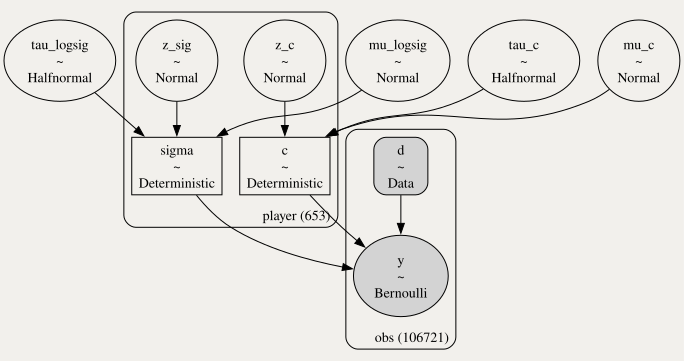

In [11]:
#| echo: false
#| label: fig-model
#| fig-cap: "The hierarchical model in graphical form. The shaded node is observed (challenge or no challenge); boxes show the dimension each variable is indexed over."

pm.model_to_graphviz(hitter_sdt, graph_attr={'bgcolor':'#F2F0EC'})

All of the variables in the model, with the exceptions of $d$ and $y$, are learned simultaneously through Markov Chain Monte Carlo sampling. In total, four sampling chains generate 1,000 draws each, which gives us posterior distributions for everything.[^diagnostics]

[^diagnostics]: For post-sampling model diagnostics, please see [the notebook on GitHub](https://github.com/chrishires/abs-sdt/blob/main/part1.ipynb).

In [12]:
#| echo: false
#| output: false

with hitter_sdt:
    hitter_trace = pm.sample(random_seed=random_seed)

NUTS[nutpie]: [mu_c, tau_c, mu_logsig, tau_logsig, z_c, z_sig]


Output()

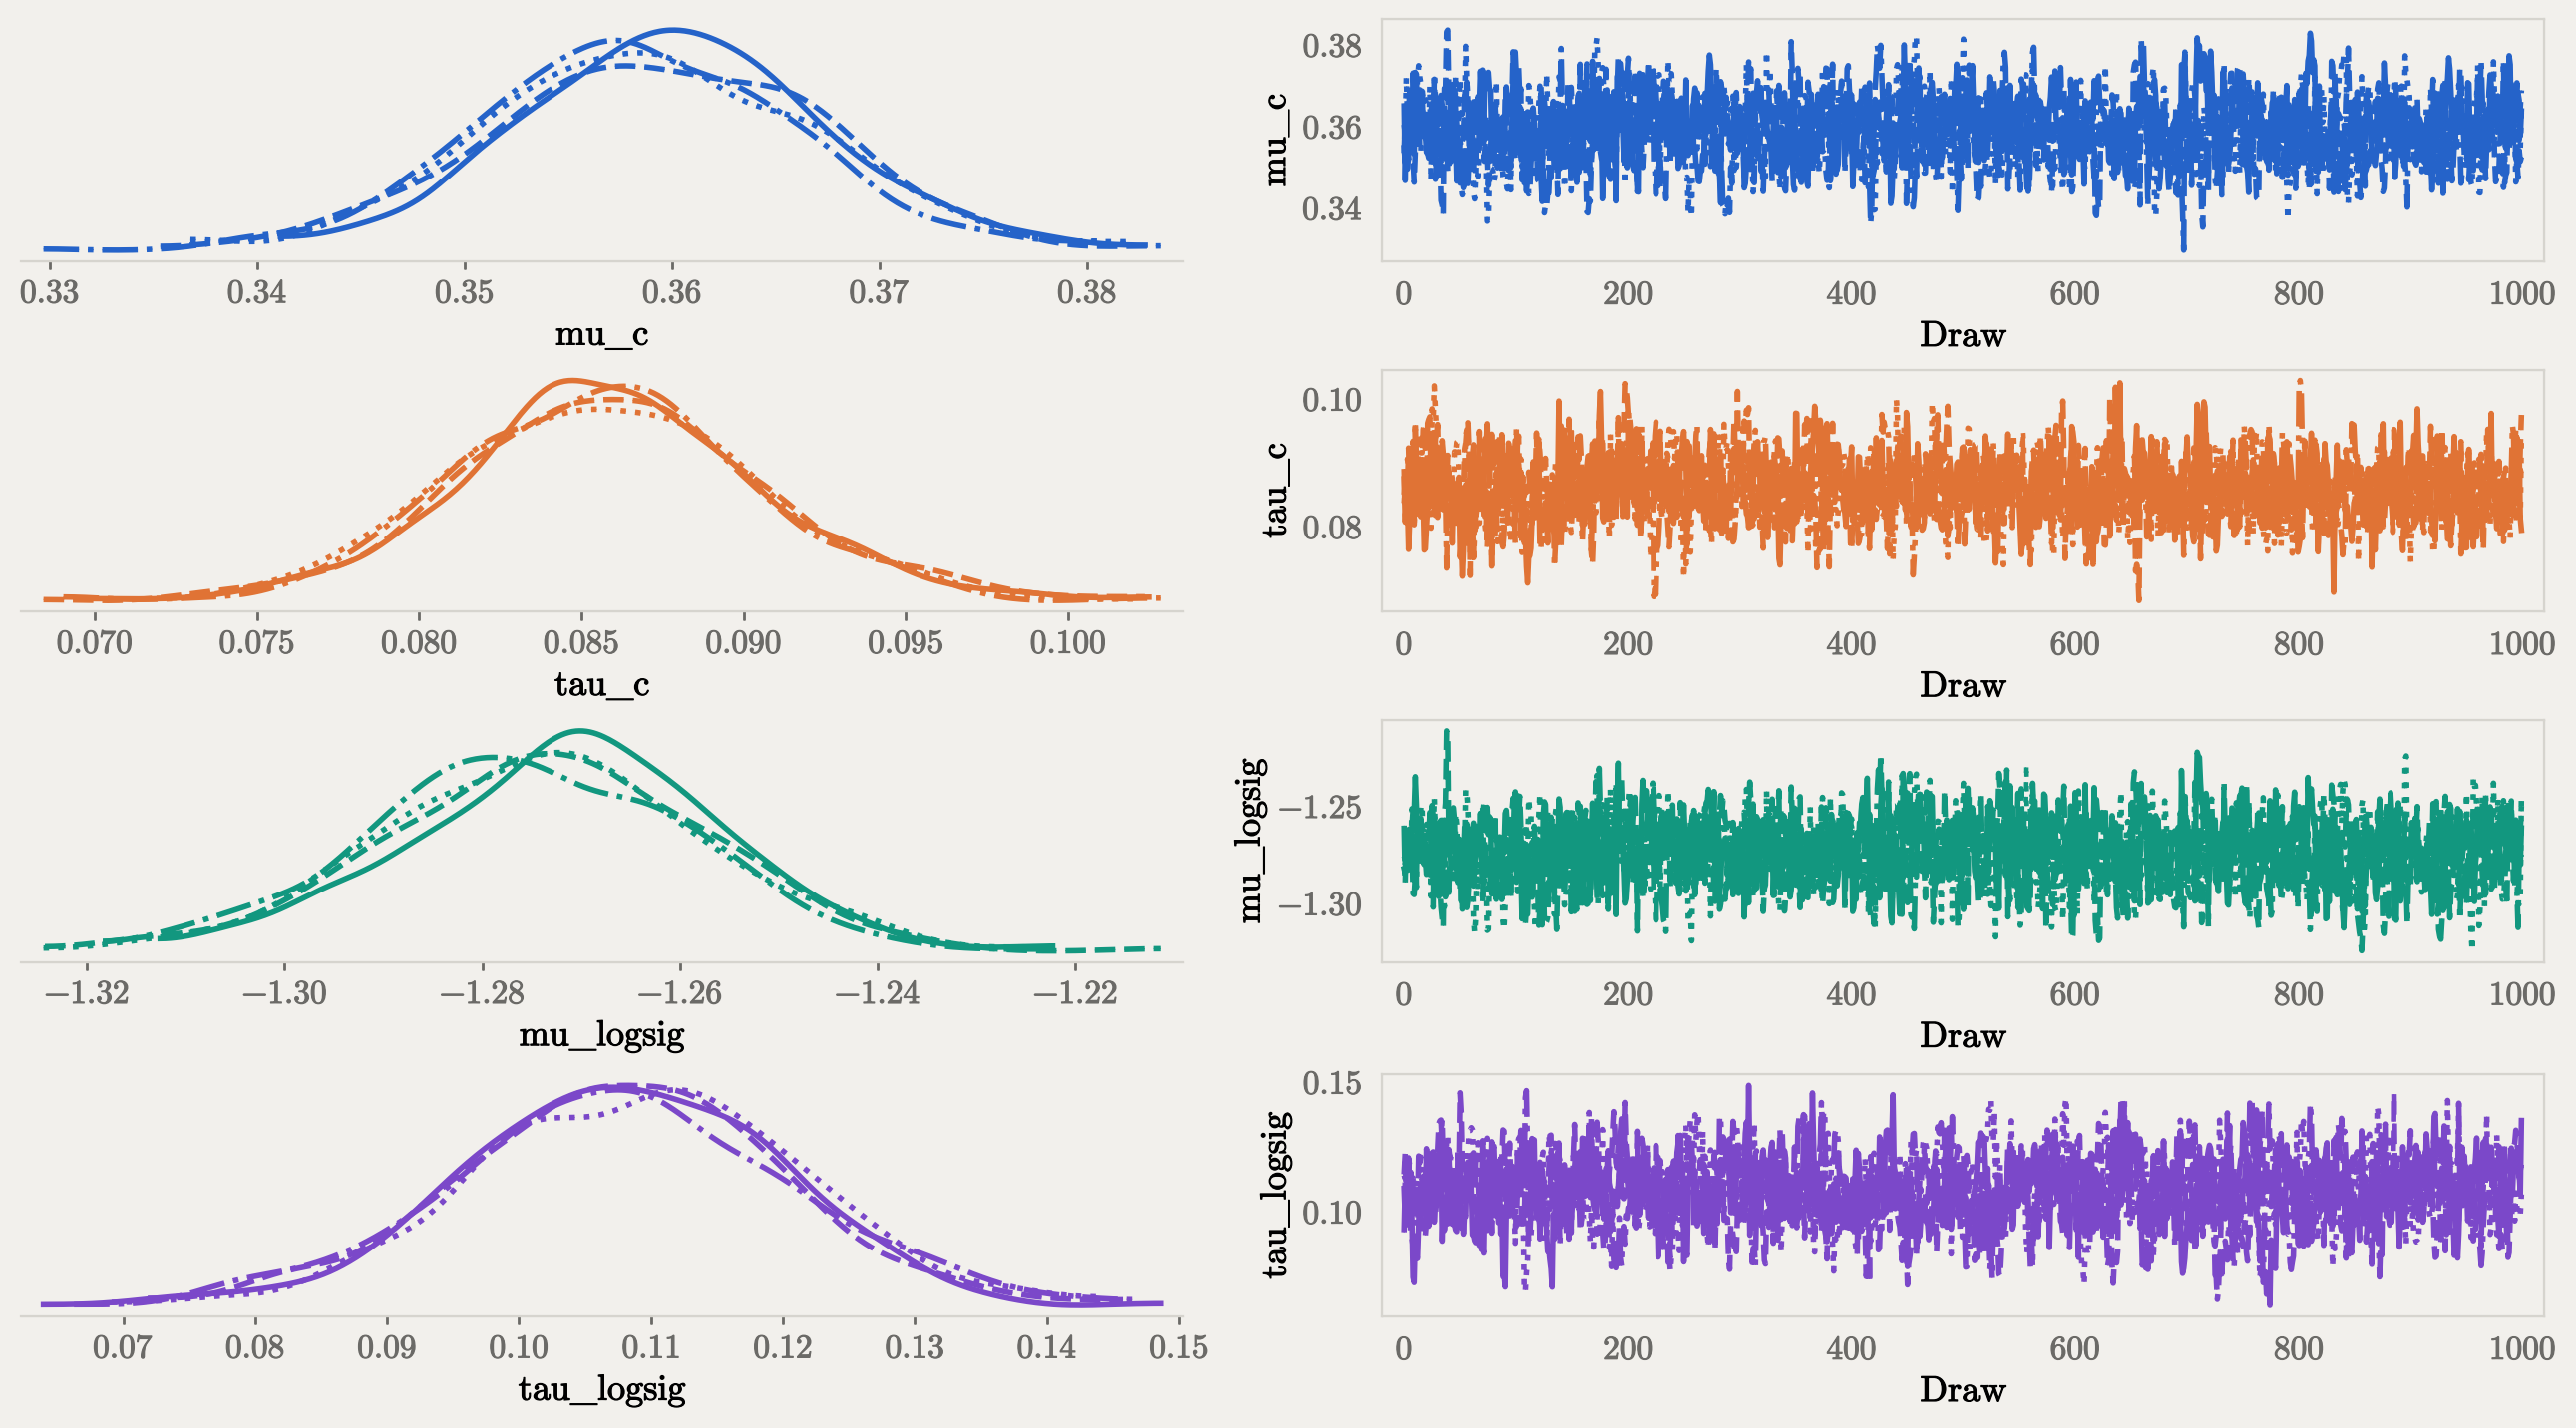

In [13]:
#| echo: false
#| output: false

az.plot_trace_dist(hitter_trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'])
plt.show()

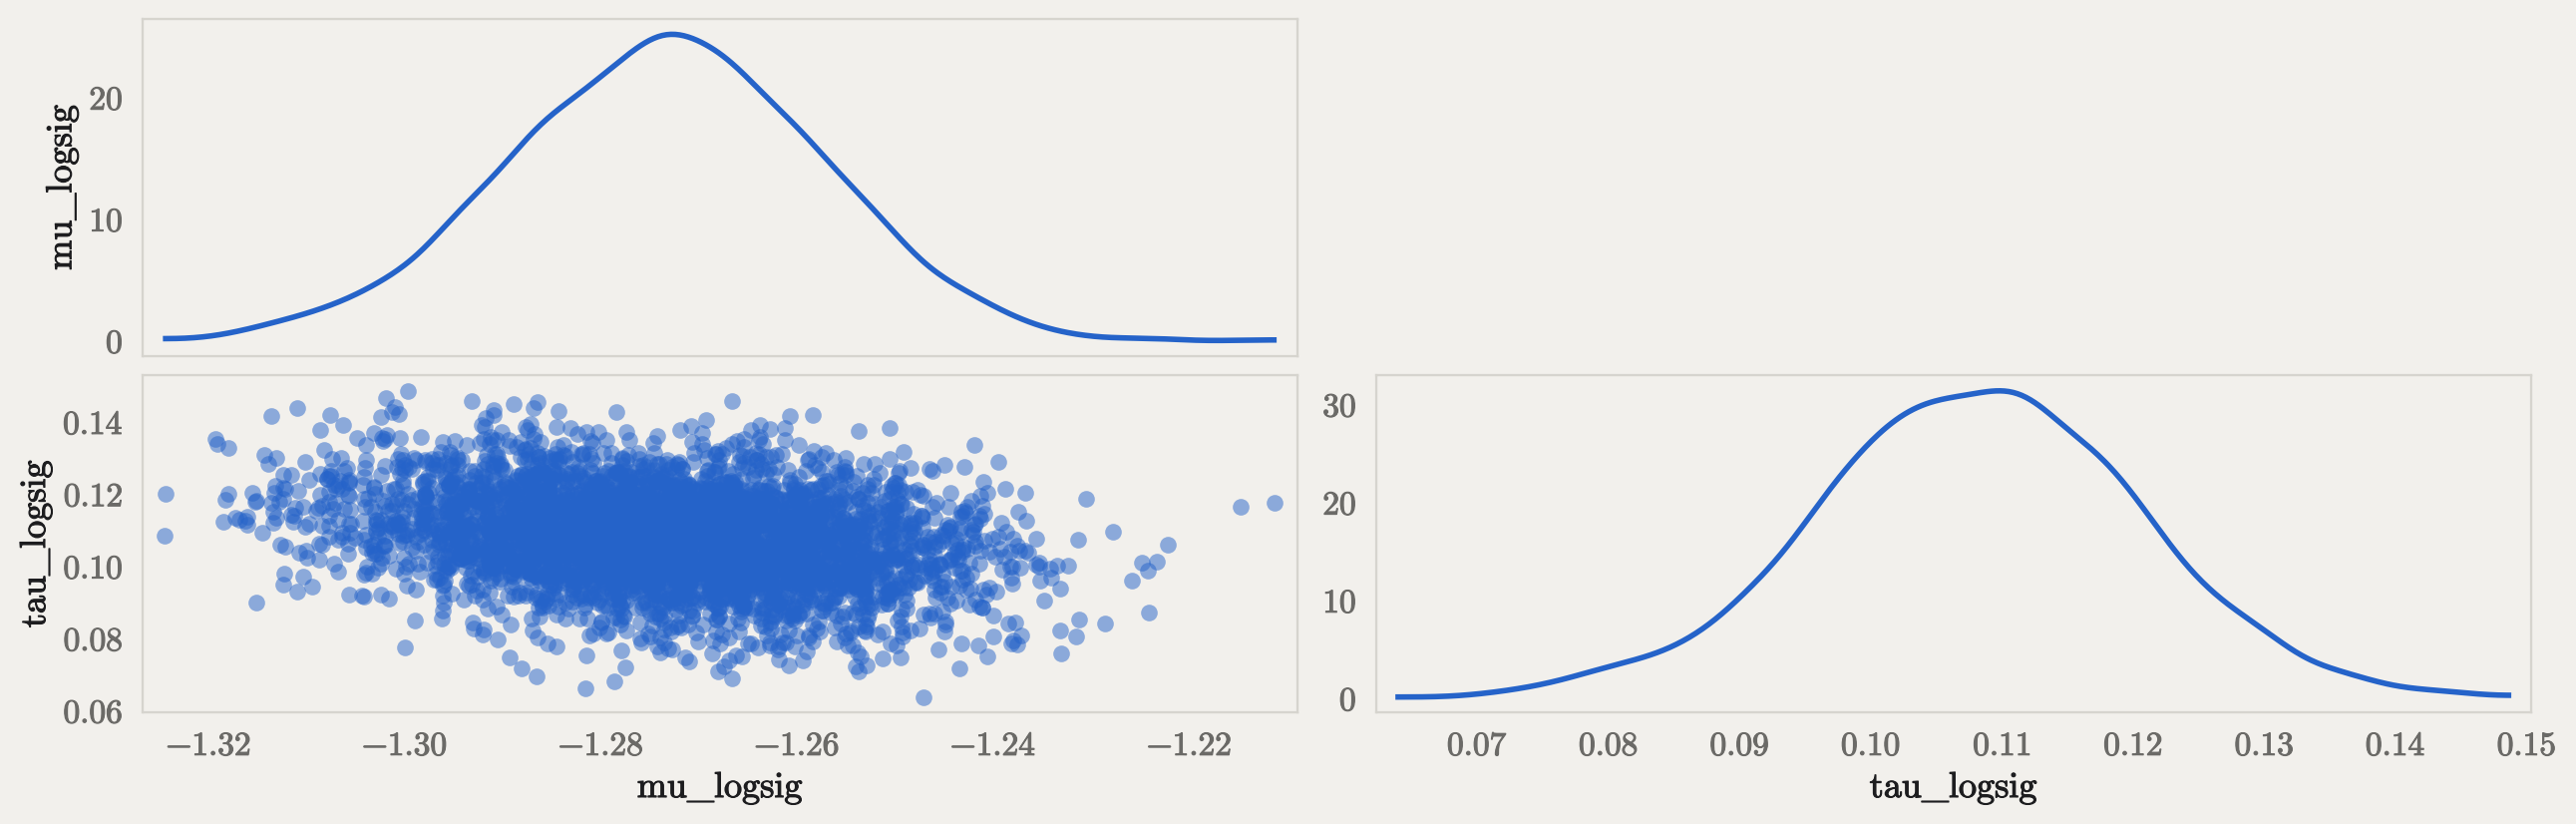

In [14]:
#| echo: false
#| output: false

az.plot_pair(hitter_trace, var_names=['mu_logsig', 'tau_logsig'])
plt.show()

## The Hitters

The signed distance from the strike zone is different depending on your perspective (positive means outside the zone for hitters, positive means inside the zone for catchers), so the model runs on each group independently. Due up first: hitters.

### Criteria

In [15]:
#| echo: false
#| label: tbl-hitter-c
#| classes: plain
#| tbl-cap: "Posterior summary of the decision criterion for hitters, in inches. `c_mean` is the typical hitter's criterion; `c_sd` is how much criteria vary from hitter to hitter."

hitter_post = hitter_trace.posterior
hitter_noise_mean = hitters[hitters['off_edge_dist'] <= 0]['off_edge_dist'].mean() * 12
hitter_signal_mean = hitters[hitters['off_edge_dist'] > 0]['off_edge_dist'].mean() * 12

hitter_vars, hitter_delta_ft = convert_to_in(hitter_post, hitter_noise_mean, hitter_signal_mean)

az.summary(hitter_vars, var_names=['c_mean','c_sd'],ci_kind='hdi', ci_prob=0.95, kind='stats', round_to=2)

,mean,sd,hdi95_lb,hdi95_ub
c_mean,4.31,0.09,4.13,4.49
c_sd,1.03,0.06,0.92,1.14


The table above shows the model's estimate of the distribution $c$, converted to inches. The `mean` column is the average across 4,000 posterior draws, `sd` is the standard deviation across those draws, and the `hdi95` columns give the range that contains the parameter with 95% posterior probability.

`c_mean` and `c_sd` describe the distribution of $c$ across all MLB hitters. For hitters, the average criterion is $c = 4.31$ inches, meaning a typical hitter needs to perceive the ball 4.31" off the plate before they'll initiate a challenge in 50% of cases. The average missed call, though, is $d=1.06$ inches off the plate, so this is quite conservative!

The standard deviation of $c$ across the hitter population is also fairly wide. Roughly 33% of players will have a $c$ more than one inch above or below the mean. In other words, hitters' thresholds for challenging a missed call are all over the place, and **this is the primary differentiator of hitter challenge behavior**. You can see that $c$ varies widely in the plot below:

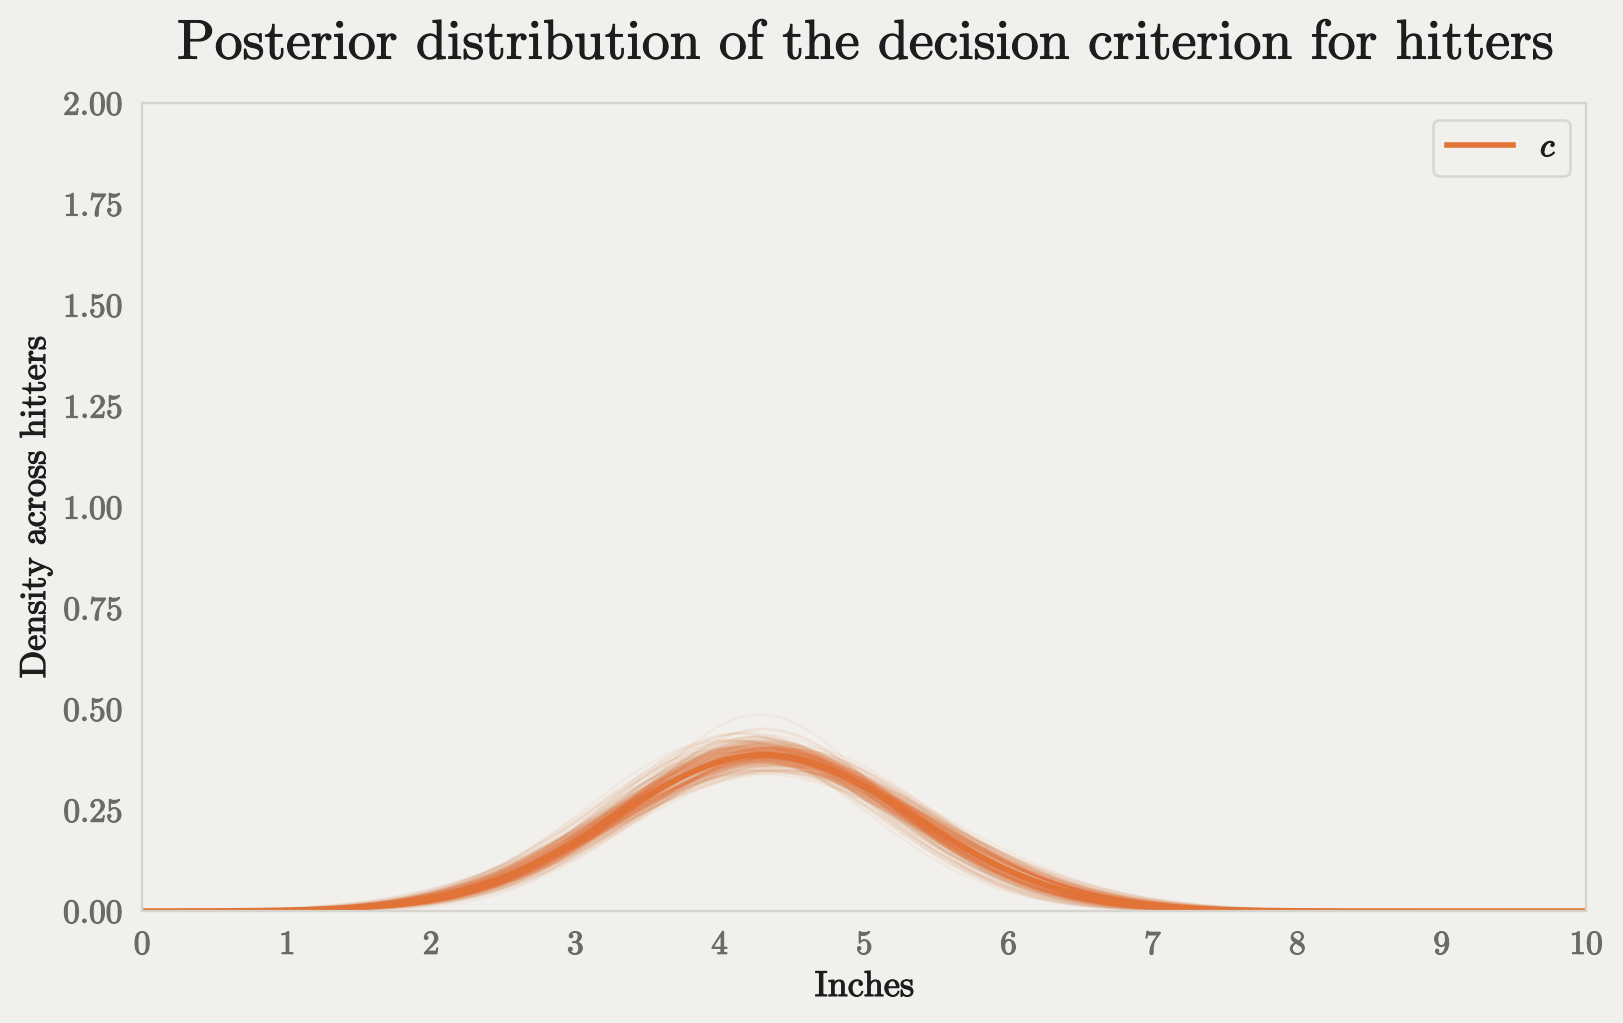

In [16]:
#| echo: false
#| label: fig-hitter-c
#| fig-cap: "Distribution of the decision criterion $c$ across hitters, in inches. The solid line uses the posterior means of $\\mu_c$ and $\\tau_c$; the faint lines are 200 random posterior draws, showing the uncertainty in that distribution."

mu_c       = hitter_post['mu_c'].values.ravel() * 12      # feet -> inches
tau_c      = hitter_post['tau_c'].values.ravel() * 12
mu_logsig  = hitter_post['mu_logsig'].values.ravel()
tau_logsig = hitter_post['tau_logsig'].values.ravel()

x = np.linspace(0.01, 10, 800)
rng = np.random.default_rng(random_seed)
draws = rng.choice(len(mu_c), 200, replace=False)

fig, ax = plt.subplots(figsize=(8, 5))

# Faint curves: 200 posterior draws, showing uncertainty in the population parameters
for i in draws:
    ax.plot(x, stats.norm.pdf(x, mu_c[i], tau_c[i]), color='C1', alpha=0.04, lw=1)

# Solid curves: posterior-mean population distributions
ax.plot(x, stats.norm.pdf(x, mu_c.mean(), tau_c.mean()), color='C1', label='$c$')

plt.xlim(0, 10)
plt.ylim(0, 2)
plt.xticks(np.arange(0, 11, 1))
ax.set_xlabel('Inches')
ax.set_ylabel('Density across hitters')
plt.title('Posterior distribution of the decision criterion for hitters')
ax.legend()
plt.show()


### Sensitivity

In [17]:
#| echo: false
#| classes: plain
#| label: tbl-hitter-dp
#| tbl-cap: "Posterior summary of challenge sensitivity for hitters. `d_prime_mean` is the typical hitter's $d'$; `d_prime_sd` is how much $d'$ varies from hitter to hitter."

az.summary(hitter_vars, var_names=['d_prime_mean', 'd_prime_sd'], ci_kind='hdi', ci_prob=0.95, kind='stats', round_to=2)

,mean,sd,hdi95_lb,hdi95_ub
d_prime_mean,1.46,0.02,1.41,1.51
d_prime_sd,0.16,0.02,0.12,0.20


By contrast, hitters' sensitivity barely varies at all. A typical hitter has a $d' = 1.46$, and hitters vary around that mean by 0.16, or about 11%. The interval for the standard deviation - 0.12 to 0.20 - excludes zero, so we can confidently say they do vary *some*, but only by a small degree.

So almost all hitters have a similar ability to differentiate between missed calls and correct calls, and the variation we see in challenge behavior is derived almost entirely from the location of a player's criterion.

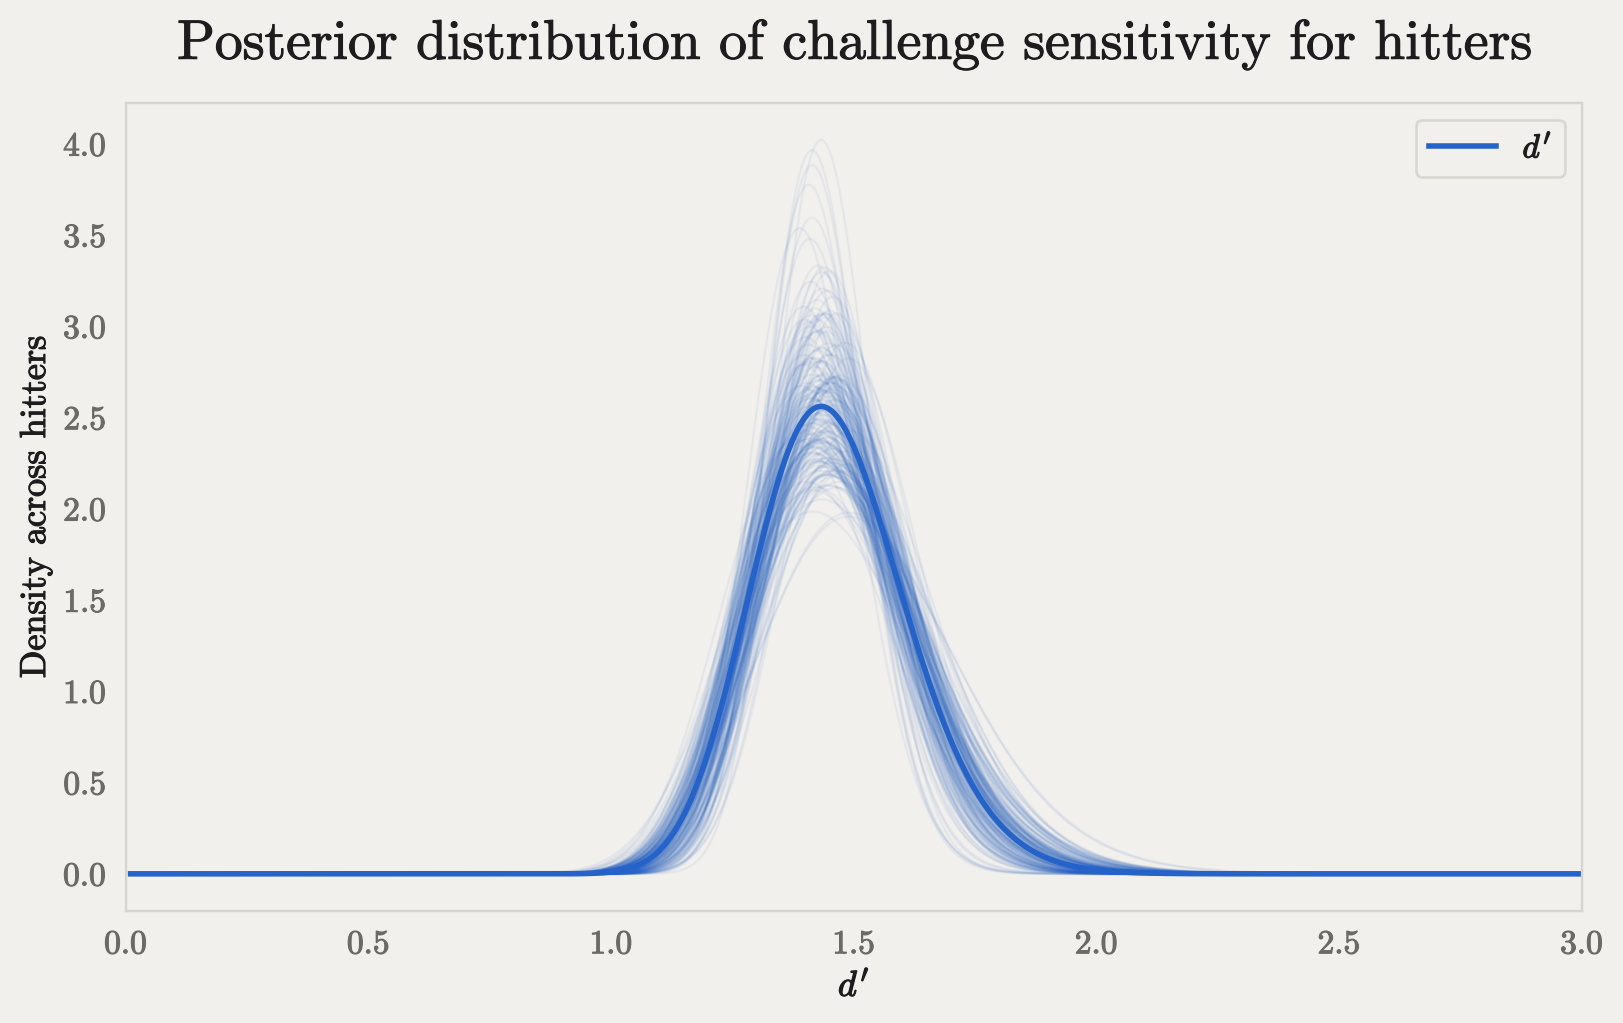

In [18]:
#| echo: false
#| label: fig-hitter-dp
#| fig-cap: "Distribution of challenge sensitivity $d'$ across hitters. The solid line uses the posterior means of $\\mu_{\\log\\sigma}$ and $\\tau_{\\log\\sigma}$; the faint lines are 200 random posterior draws, showing the uncertainty in that distribution."

mu_c       = hitter_post['mu_c'].values.ravel() * 12      # feet -> inches
tau_c      = hitter_post['tau_c'].values.ravel() * 12
mu_logsig  = hitter_post['mu_logsig'].values.ravel()
tau_logsig = hitter_post['tau_logsig'].values.ravel()




x = np.linspace(0.01, 3, 800)
rng = np.random.default_rng(random_seed)
draws = rng.choice(len(mu_c), 200, replace=False)

fig, ax = plt.subplots(figsize=(8, 5))

# Faint curves: 200 posterior draws, showing uncertainty in the population parameters
for i in draws:
    ax.plot(x, stats.lognorm.pdf(x, s=tau_logsig[i], scale=hitter_delta_ft * np.exp(-mu_logsig[i])),
            color='C0', alpha=0.04, lw=1)

# Solid curves: posterior-mean population distributions
ax.plot(x, stats.lognorm.pdf(x, s=tau_logsig.mean(), scale=hitter_delta_ft * np.exp(-mu_logsig.mean())),
        color='C0', label=r"$d'$")

plt.xlim(0, 3)
ax.set_ylabel('Density across hitters')
ax.set_xlabel(r"$d'$")
plt.title('Posterior distribution of challenge sensitivity for hitters')
ax.legend()
plt.show()


### Hitter Comparisons

Here are the ten most aggressive hitters, i.e., the players with the lowest $c$. These are the players who will typically challenge even when the ball only appears a couple inches off the plate.

In [19]:
#| echo: false
#| label: tbl-hitter-aggressive
#| tbl-cap: "The ten most aggressive hitters (lowest criterion $c$, in inches), with their $d'$. `_ci_lb` and `_ci_ub` are the bounds of each 95% credible interval."

hitter_summary = build_summary(hitter_trace, hitters, 'batter_id', 'batter', hitter_noise_mean, hitter_signal_mean)
hitter_summary[['player_name','c_mean','c_ci_lb','c_ci_ub','d_prime_mean','d_prime_ci_lb','d_prime_ci_ub']].sort_values(by='c_mean', ascending=True).head(10).round(2)

,player_name,c_mean,c_ci_lb,c_ci_ub,d_prime_mean,d_prime_ci_lb,d_prime_ci_ub
player,,,,,,,
547180,Bryce Harper,1.25,0.36,2.06,1.55,1.23,1.84
596142,Gary Sánchez,1.54,0.55,2.47,1.44,1.18,1.74
668901,Mark Vientos,1.87,0.82,2.92,1.44,1.17,1.74
694384,Nolan Schanuel,2.00,1.13,2.89,1.53,1.22,1.82
701398,Sal Stewart,2.08,1.26,2.88,1.59,1.29,1.91
694249,Cole Carrigg,2.10,1.00,3.11,1.37,1.11,1.64
687282,Gabriel Rincones Jr.,2.24,0.65,3.81,1.42,1.14,1.75
665923,Esteury Ruiz,2.28,1.09,3.41,1.37,1.13,1.65
514888,Jose Altuve,2.34,1.43,3.28,1.45,1.20,1.73


Baseball fans may not be surprised to see Bryce Harper's name at the top of the list. Harper's $c$ is 1.25, which is only 0.19 inches more than the average signed distance of a missed call. Not only is he the most aggressive, he's 19% more aggressive than his nearest neighbor, Gary Sánchez, and twice as aggressive as the tenth hitter, Munetaka Murakami. 

Here's his SDT plot - note where his criterion line falls on the signal curve:

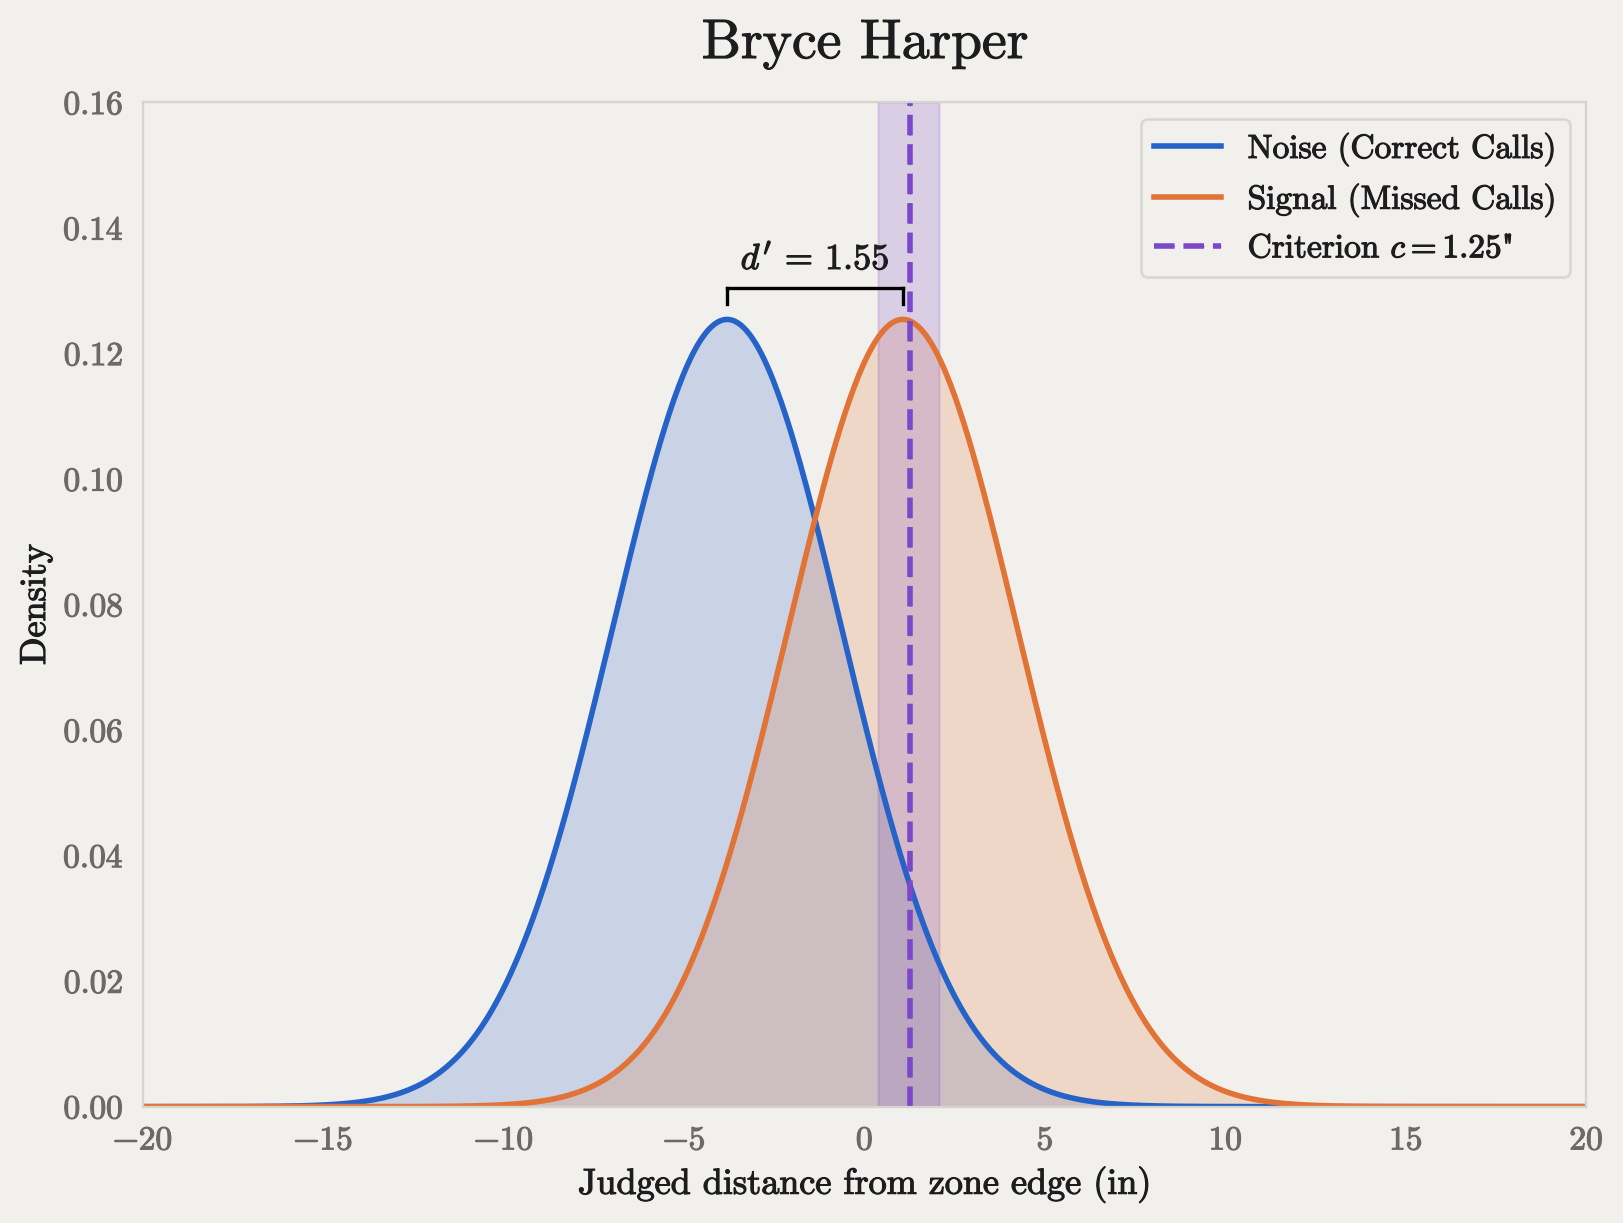

In [20]:
#| echo: false
#| label: fig-harper
#| fig-cap: "SDT plot for Bryce Harper, the most aggressive hitter. The shaded band is the 95% credible interval for his criterion."

plot_sdt('547180', hitter_summary, hitter_noise_mean, hitter_signal_mean, y_max=0.16)

If you set your $c$ that close to the strike zone, you'd better be ok with missing a few challenges here and there. Harper challenged 47 times in the 2026 regular season - the second most as a hitter after Sal Stewart's 51 - but succeeded on only 45% of them.

Harper took 288 challengeable called strikes in the 2026 season, and 256 of them were called correctly. From those 256 pitches the model expects about 26 false positives. His actual false positive count was 26, so the model nails it. The model does undersell him on the missed calls, though: it expects about 15 successful challenges, and he had 21.

In [21]:
#| echo: false
#| output: false

# Model check for Harper: expected false/true positives from his fitted curve
harper = hitters[hitters['batter_id'] == 547180]
harper_row = hitter_summary.loc['547180']
p_challenge = stats.norm.cdf((harper['off_edge_dist'].to_numpy() * 12 - harper_row['c_mean']) / harper_row['sigma_mean'])
correct = (harper['off_edge_dist'] <= 0).to_numpy()

print(f"correct calls: {correct.sum()}, missed calls: {(~correct).sum()}")
print(f"expected FP: {p_challenge[correct].sum():.1f}, actual FP: {harper['FP'].sum()}")
print(f"expected TP: {p_challenge[~correct].sum():.1f}, actual TP: {harper['TP'].sum()}")


correct calls: 256, missed calls: 32
expected FP: 25.8, actual FP: 26
expected TP: 14.5, actual TP: 21


For contrast, here are the least aggressive players, those with the highest $c$:

In [22]:
#| echo: false
#| label: tbl-hitter-conservative
#| tbl-cap: "The ten most conservative hitters (highest criterion $c$, in inches), with their $d'$. `_ci_lb` and `_ci_ub` are the bounds of each 95% credible interval."

hitter_summary[['player_name','c_mean','c_ci_lb','c_ci_ub','d_prime_mean','d_prime_ci_lb','d_prime_ci_ub']].sort_values(by='c_mean', ascending=False).head(10).round(2)

,player_name,c_mean,c_ci_lb,c_ci_ub,d_prime_mean,d_prime_ci_lb,d_prime_ci_ub
player,,,,,,,
650490,Yandy Díaz,6.56,5.20,7.96,1.68,1.36,2.00
683734,Andrew Vaughn,6.31,4.89,7.69,1.65,1.32,1.98
596019,Francisco Lindor,6.17,4.86,7.54,1.58,1.28,1.86
807713,Matt Shaw,5.90,4.46,7.28,1.13,0.96,1.31
664770,Nathan Lukes,5.88,4.36,7.36,1.62,1.32,1.95
686948,Drake Baldwin,5.86,4.46,7.26,1.61,1.31,1.93
664040,Brandon Lowe,5.80,4.40,7.03,1.60,1.32,1.89
660688,Keibert Ruiz,5.76,4.18,7.34,1.59,1.29,1.92
670541,Yordan Alvarez,5.71,4.39,7.11,1.57,1.30,1.88


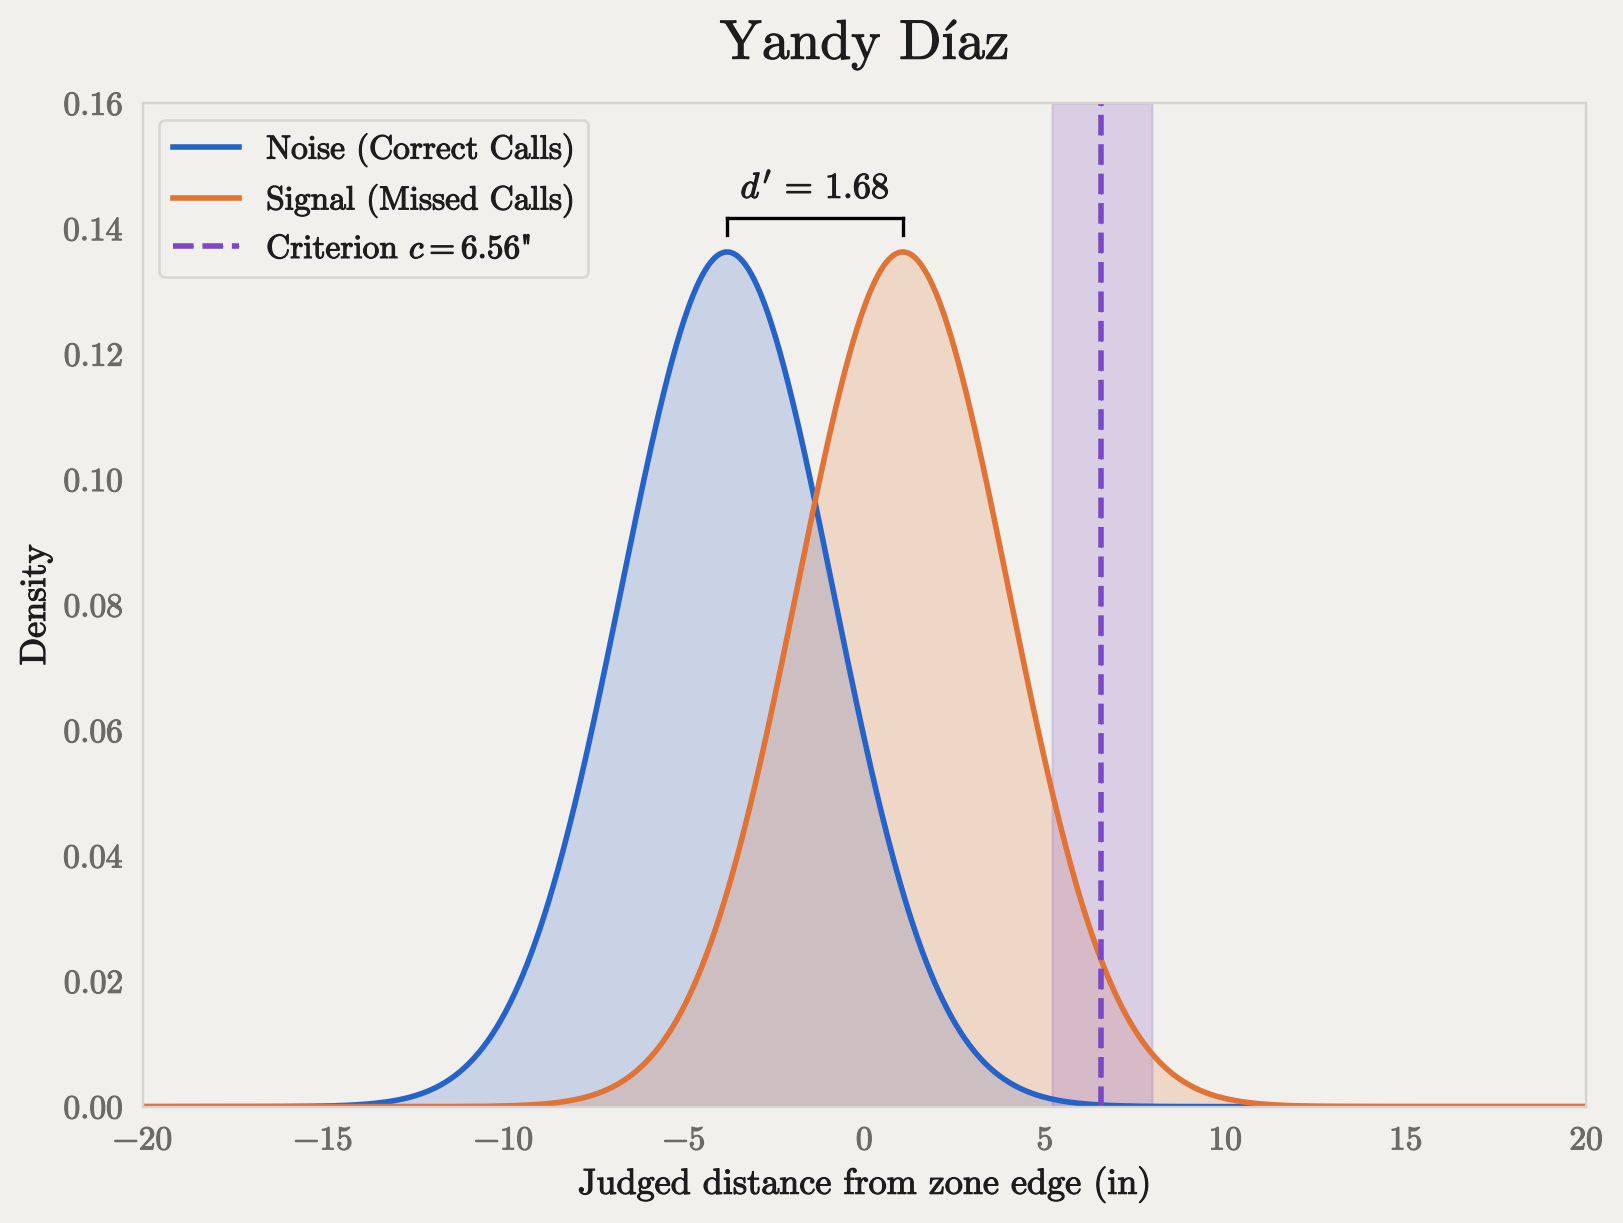

In [23]:
#| echo: false
#| label: fig-diaz
#| fig-cap: "SDT plot for Yandy Díaz, the most conservative hitter. With no challenges to learn from, his criterion's credible interval is wide."

plot_sdt('650490',hitter_summary, hitter_noise_mean, hitter_signal_mean, y_max=0.16)

Yandy Díaz is unusually conservative. He took 411 called strikes in the 2026 season. Of those, 54 were miscalled, and should have been balls. Díaz didn't challenge a single one. As it turns out, for better or worse, Yandy refuses to challenge pitches [as a matter of personal policy](https://www.tampabay.com/sports/rays/2026/06/20/yandy-diaz-american-league-leaders-designated-hitter/):

>
>There are some things Diaz doesn’t budge on.
>
>One is that he only hits in the cages rather than take batting practice on the field. Another is that he picks the design for his black face paint each game.
>
>Of more note, he refuses to embrace the new ABS system to challenge calls on pitches, despite urging from coaches.
>
>Given what seems a keen knowledge of the strike zone, Diaz has on several occasions given an umpire a long look, but not, as 421 other hitters have done, tapped his helmet for the computer-assisted chance for correction.
>
>“I don’t like it,” he said. “When I go to home plate, I need a hit not a challenge. … Maybe in the World Series some time, but now (no)."
>

You can see his criterion is all the way at the edge of the signal distribution and effectively beyond the noise distribution (he has no false positives), with a wide credible interval. Díaz never challenged a single pitch, so his data can only tell us that his criterion is beyond the distance of every missed call he saw, but we can't know how far beyond. The model makes a guess by borrowing from the population of hitters, which is why his estimate is high but uncertain.

On one hand, he's extremely accurate: because most called strikes are correct, never challenging means being right about 87% of the time. But his conservative policy carries real costs, which we'll measure in Part 2.

Nearly all hitters have $d'$ credible intervals that overlap the population interval, which means we can't really say that most of them are more or less sensitive than the typical hitter. As we discussed above, they all cluster very closely together. There are a few exceptions, though, and they are the hitters with the lowest $d'$, aka, the least sensitive hitters:

In [24]:
#| echo: false
#| label: tbl-hitter-low-dp
#| tbl-cap: "The ten hitters with the lowest challenge sensitivity $d'$, with their criterion $c$ in inches. `_ci_lb` and `_ci_ub` are the bounds of each 95% credible interval."

hitter_summary[['player_name','c_mean','c_ci_lb','c_ci_ub','d_prime_mean','d_prime_ci_lb','d_prime_ci_ub']].sort_values(by='d_prime_mean', ascending=True).head(10).round(2)

,player_name,c_mean,c_ci_lb,c_ci_ub,d_prime_mean,d_prime_ci_lb,d_prime_ci_ub
player,,,,,,,
691406,Junior Caminero,5.49,4.34,6.63,1.05,0.90,1.21
807713,Matt Shaw,5.90,4.46,7.28,1.13,0.96,1.31
699013,Esmerlyn Valdez,4.41,3.19,5.63,1.15,0.96,1.33
683748,Victor Mesa Jr.,4.05,2.67,5.36,1.20,0.99,1.40
669397,Nick Allen,5.13,3.70,6.63,1.20,1.00,1.40
691718,Pete Crow-Armstrong,4.55,3.47,5.69,1.20,1.02,1.37
800325,Luis Lara,5.09,3.72,6.38,1.22,1.03,1.43
575929,Willson Contreras,3.34,2.26,4.45,1.28,1.07,1.52
655316,Andruw Monasterio,5.56,4.27,6.85,1.29,1.07,1.49


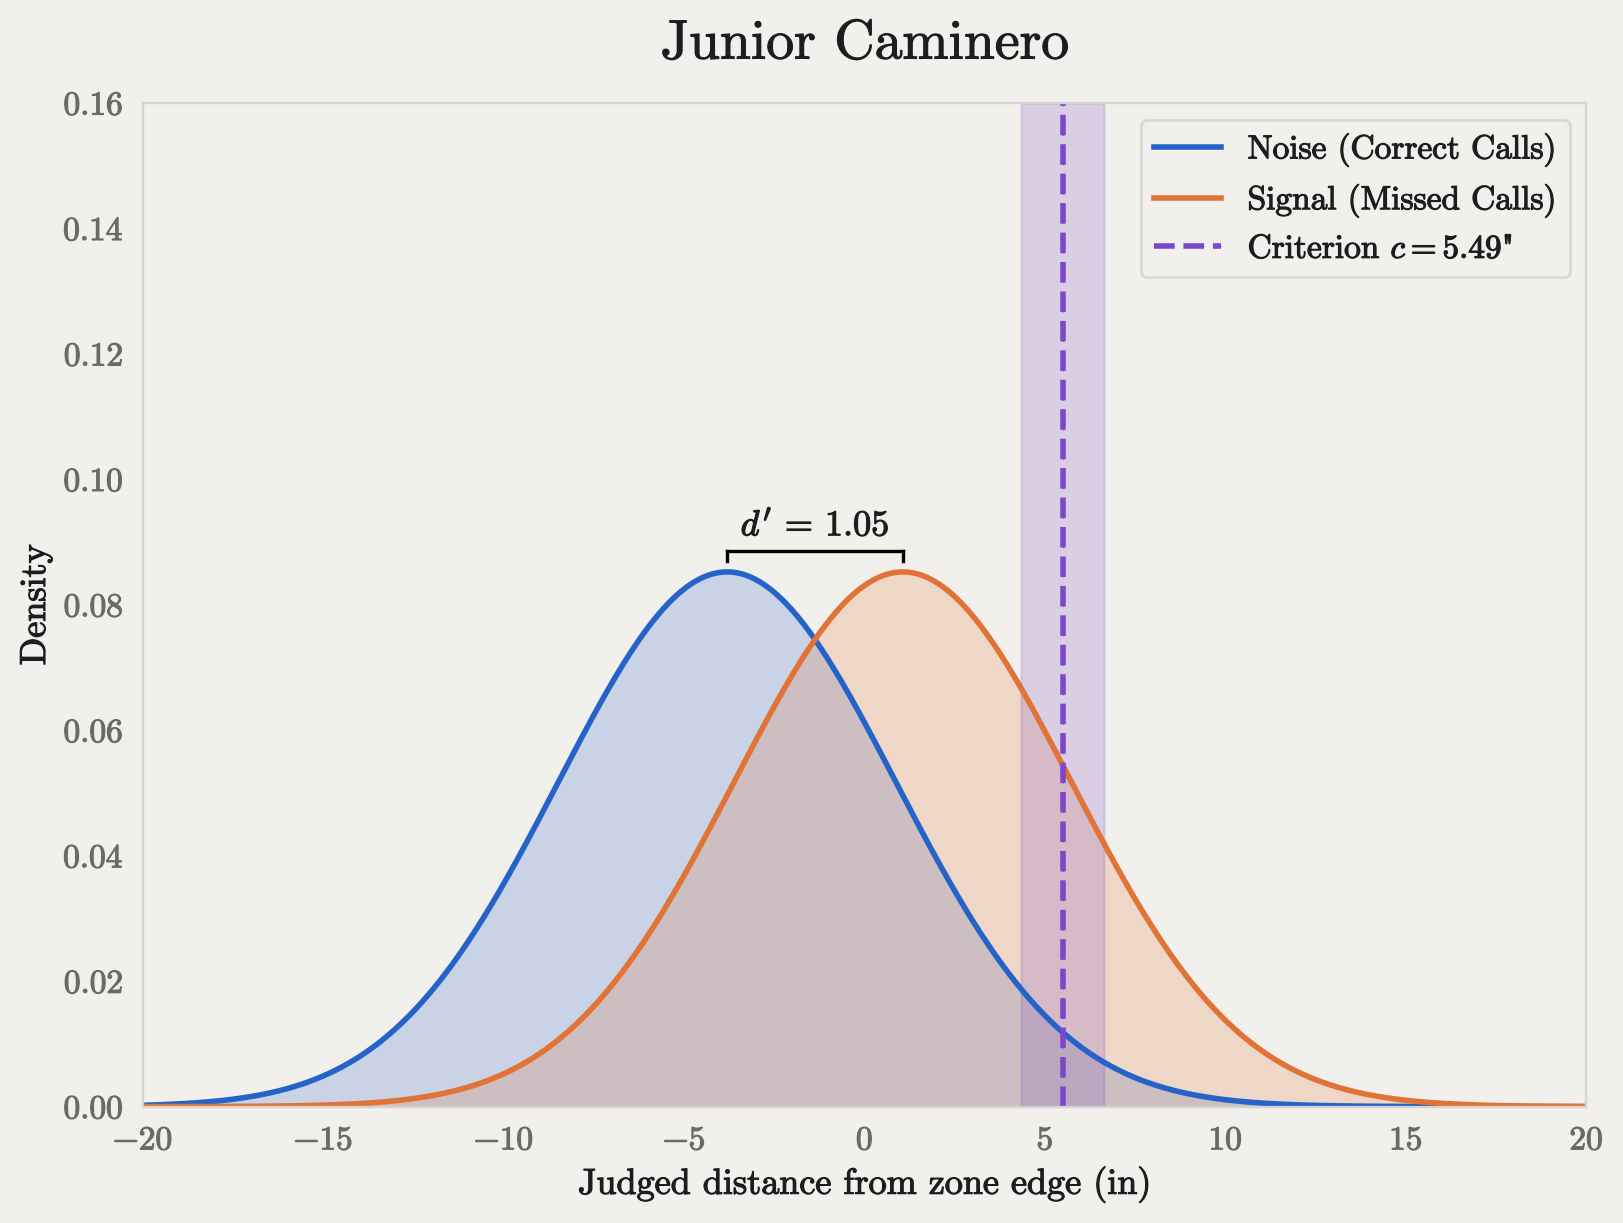

In [25]:
#| echo: false
#| label: fig-caminero
#| fig-cap: "SDT plot for Junior Caminero, the hitter with the lowest $d'$. Note the heavier overlap between the two curves."

plot_sdt('691406',hitter_summary, hitter_noise_mean, hitter_signal_mean, y_max=0.16)

Yandy's Tampa Bay teammate, Junior Caminero, has the lowest $d'$ of any hitter. At $d'=1.05$, he's one of six whose sensitivity is detectably below average. His record shows why. He challenged 24 times and won only 9, so most of his challenges were spent on pitches that were actually strikes. Yet he also let 43 genuine missed calls go without a challenge.

That combination is the signature of low sensitivity rather than a misplaced criterion. A player who sets their bar too low would win less often but catch more missed calls; a player who sets it too high would catch fewer but win more of the ones they tried. Caminero does poorly on both at once. His criterion is actually on the conservative side; the problem is that his challenges don't line up closely with where the pitch was.

That said, 1.05 isn't zero; he isn't guessing. If he'd picked 24 pitches to challenge at random, the chance of winning 9 or more is about 0.2%. And it says nothing about how well he sees the ball when he swings. It's a measure of how closely his *challenge decisions* track the location of the pitch, and on that measure, he's at the bottom of the league. He was also 6th in slugging percentage (.524) and 4th in home runs (42),[^bb_ref] so he's doing just fine.

[^bb_ref]: Per Junior's [Baseball Reference page](https://www.baseball-reference.com/players/c/caminju01.shtml).

In [26]:
#| echo: false
#| output: false

# Only pitches where the fielding team still had a challenge left (Savant's definition of an opportunity)
catchers =  data[data['originalCallCode'].isin(['B','*B']) & (data['pre_fielding_challenges'] > 0)][['catcher_id','catcher','pitcher_id','pitcher','review_player_id','def_edge_dist','TP','FP','TN','Def_FN']]
catchers['p_challenge'] = catchers['review_player_id'] == catchers['pitcher_id']
catchers = catchers[catchers['p_challenge'] == False] # Drop the pitcher challenges
catchers['challenge'] = np.where(catchers['review_player_id'] == catchers['catcher_id'],1,0)

keep_cols = ['catcher_id','catcher','review_player_id','def_edge_dist','TP','FP','TN','Def_FN','challenge']
catchers = catchers[keep_cols]

In [27]:
#| echo: false
# Data Prep

catcher_ids = catchers['catcher_id'].astype('category')
n_players = len(catcher_ids.cat.categories)
n_pitches = len(catchers)
obs_ids = np.arange(n_pitches)
catcher_idx = catcher_ids.cat.codes.to_numpy().astype('int64')
distance = catchers['def_edge_dist'].to_numpy()
challenge = catchers['challenge'].to_numpy()

In [28]:
#| echo: false

with pm.Model(coords={'player': catcher_ids.cat.categories.astype('str'), 'obs': obs_ids}) as catcher_sdt:
    
    #hypers
    mu_c = pm.Normal('mu_c', 0, 0.5)
    tau_c = pm.HalfNormal('tau_c', 0.5)
    mu_logsig = pm.Normal('mu_logsig', -0.7, 0.5)
    tau_logsig = pm.HalfNormal('tau_logsig', 0.5)

    # player offsets
    z_c = pm.Normal('z_c', 0, 1, dims='player')
    z_sig = pm.Normal('z_sig', 0, 1, dims='player')

    d = pm.Data('d', distance, dims='obs')
    c = pm.Deterministic('c', mu_c + z_c * tau_c, dims='player')
    sigma = pm.Deterministic('sigma', pm.math.exp(mu_logsig + z_sig * tau_logsig), dims='player')

    # Likelihood
    eta = ((d - c[catcher_idx]) / sigma[catcher_idx])
    p = pm.math.invprobit(eta)
    pm.Bernoulli('y', p=p, observed=challenge, dims='obs')



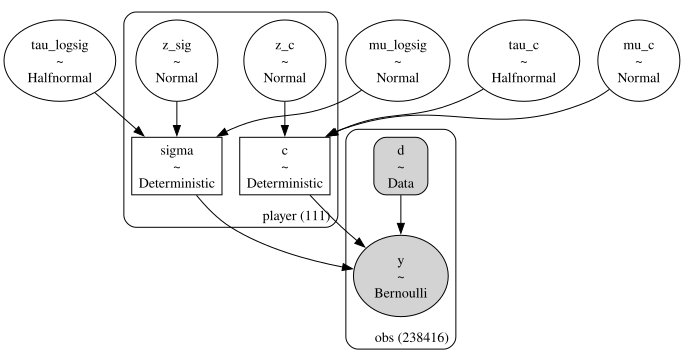

In [29]:
#| echo: false
#| output: false

pm.model_to_graphviz(catcher_sdt)

In [30]:
#| echo: false
#| output: false

with catcher_sdt:
    catcher_trace = pm.sample(random_seed=random_seed)

NUTS[nutpie]: [mu_c, tau_c, mu_logsig, tau_logsig, z_c, z_sig]


Output()

In [31]:
#| echo: false
#| output: false

az.summary(catcher_trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'], ci_kind='hdi', ci_prob=0.95)

,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_c,0.1668,0.0044,0.16,0.18,1025,1628,1.00,0.00014,9.8e-05
tau_c,0.0319,0.0036,0.025,0.04,914,1392,1.00,0.00012,8.6e-05
mu_logsig,-1.8031,0.0147,-1.8,-1.8,1487,2120,1.00,0.00038,0.00027
tau_logsig,0.0943,0.0142,0.067,0.12,963,1531,1.00,0.00045,0.00033


[]

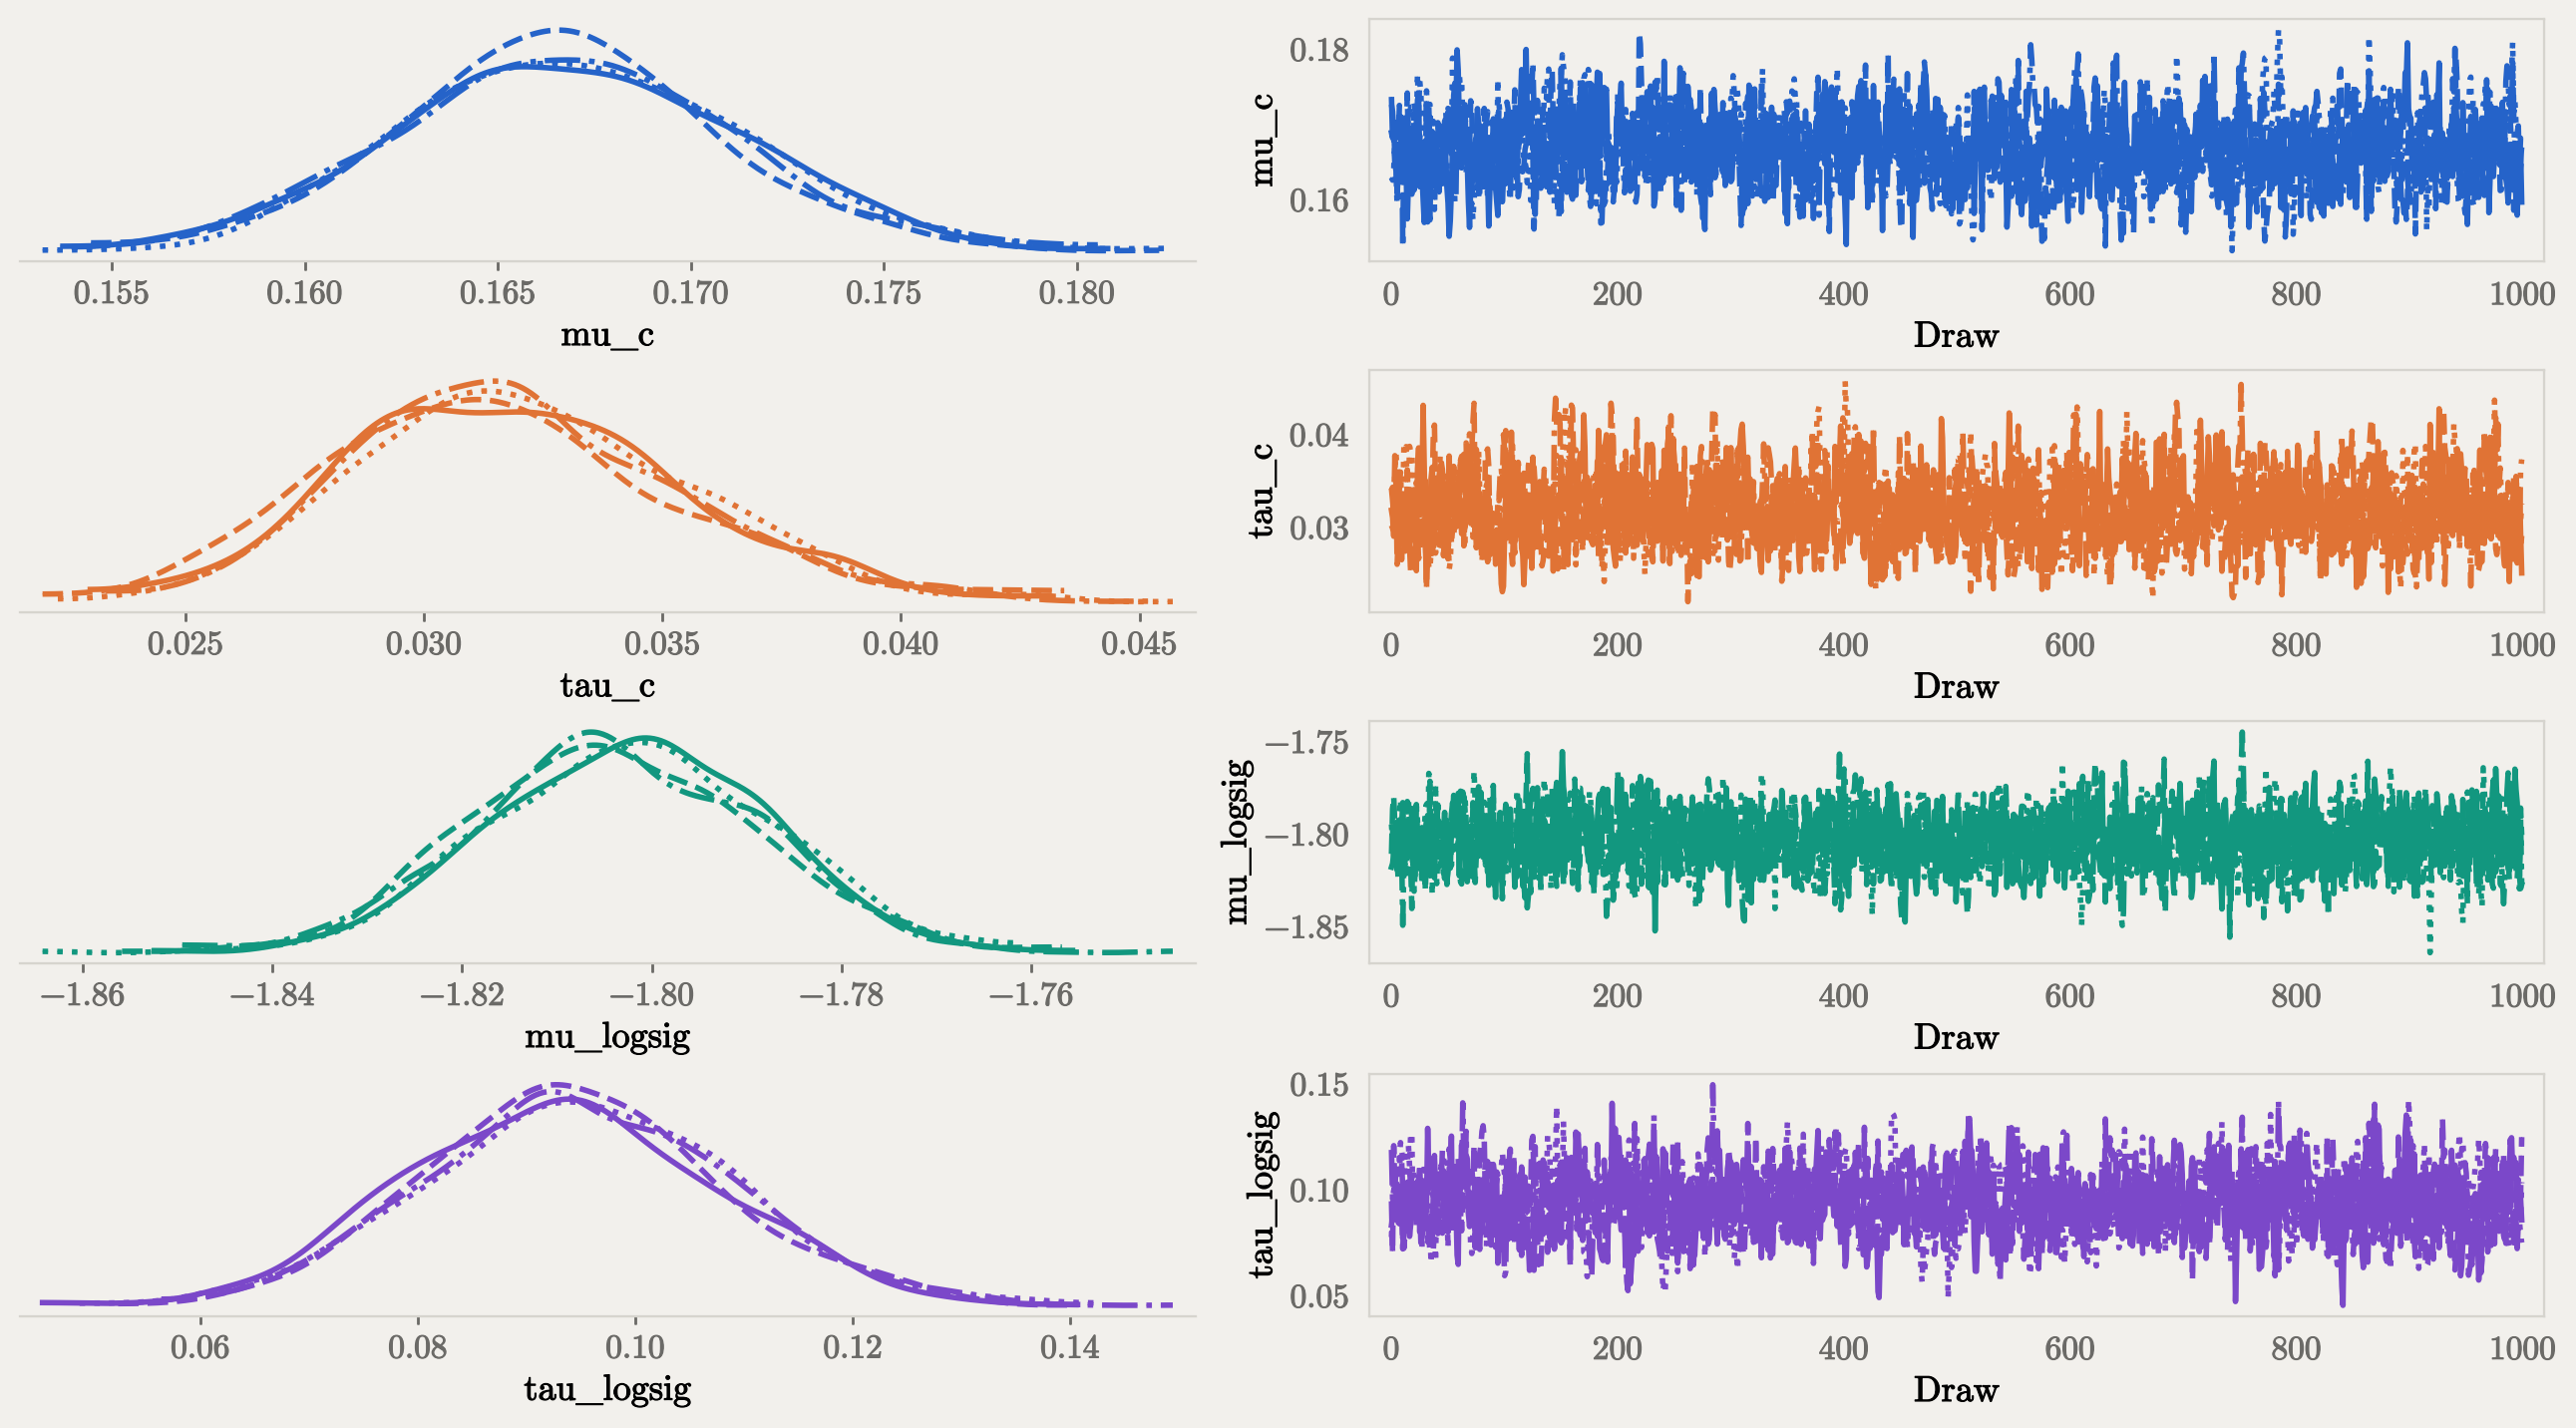

In [32]:
#| echo: false
#| output: false

az.plot_trace_dist(catcher_trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'])
plt.plot()

[]

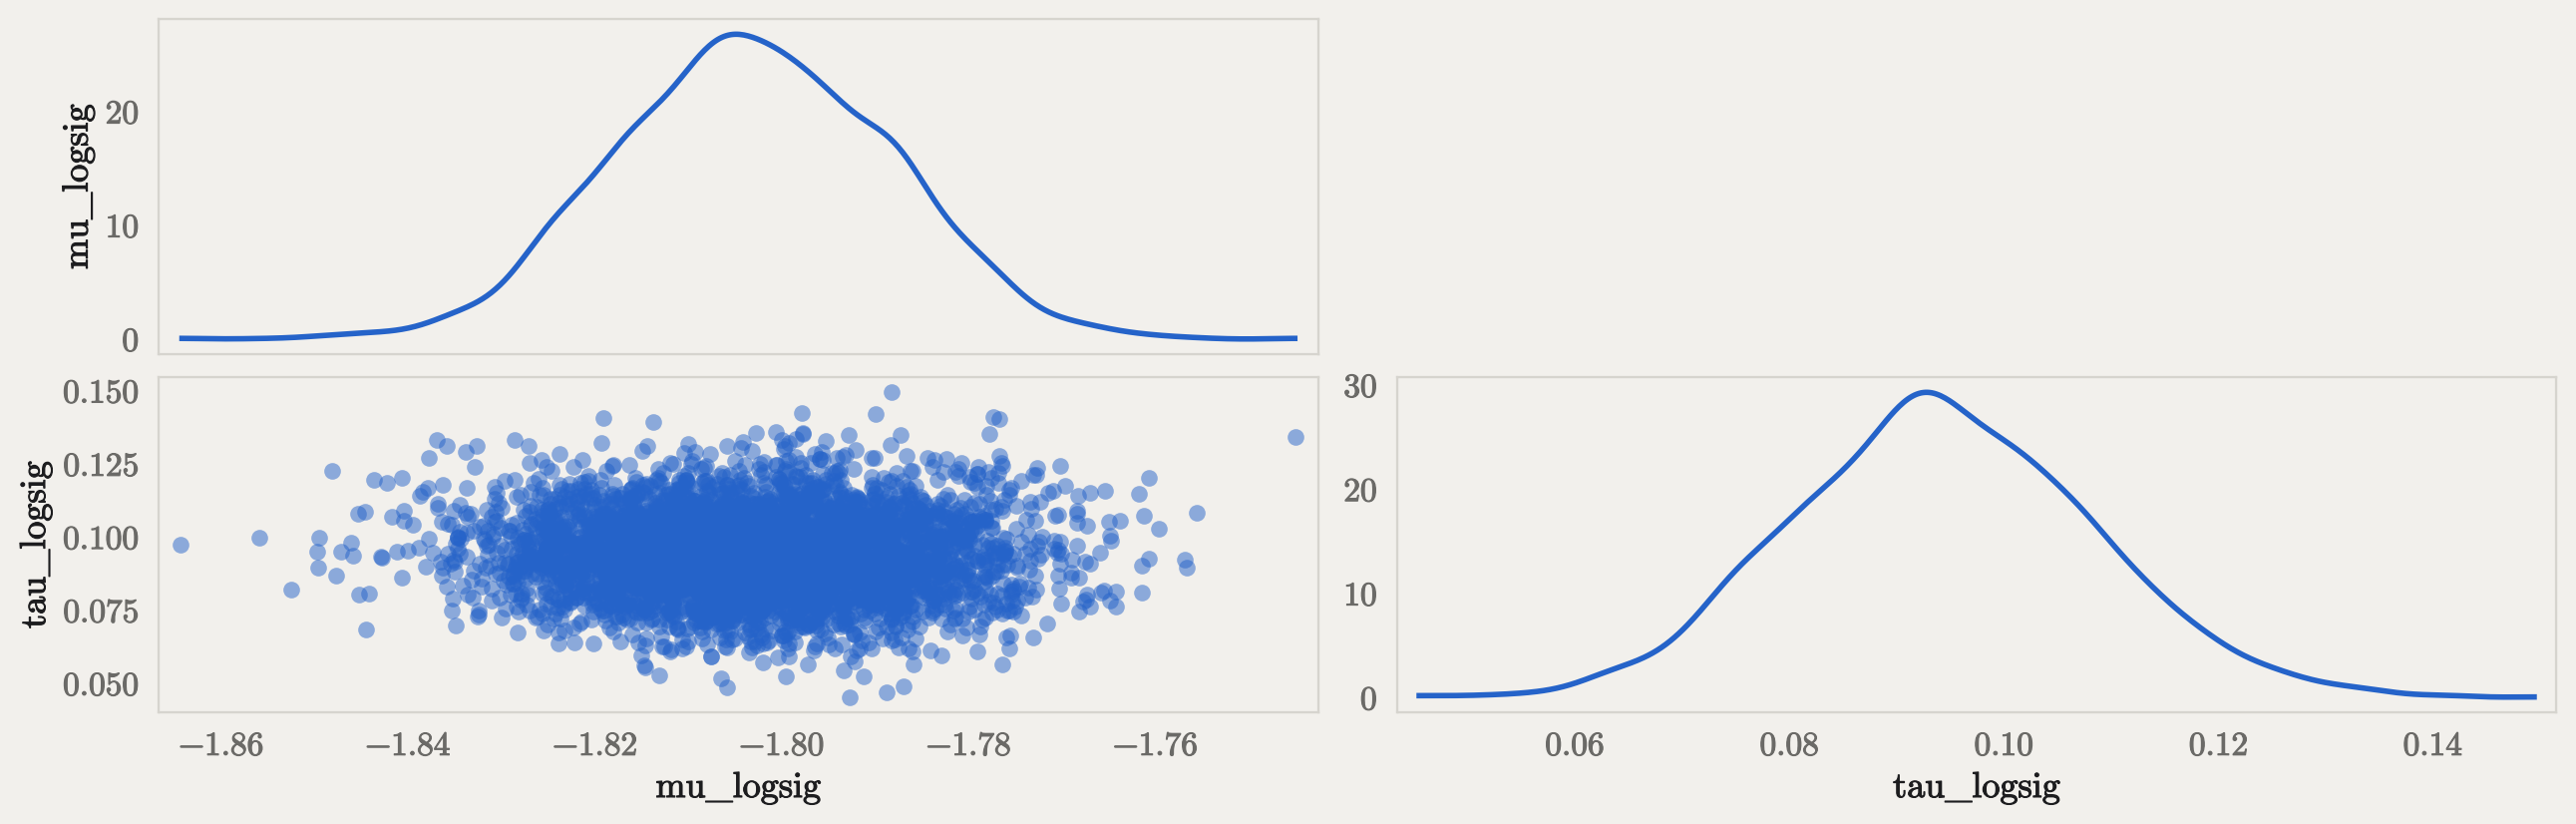

In [33]:
#| echo: false
#| output: false

az.plot_pair(catcher_trace, var_names=['mu_logsig', 'tau_logsig'])
plt.plot()

## The Catchers

There are far fewer catchers (111) than hitters (653), but catchers see many more pitches in each game, which means we get many more opportunities to observe their decisions. The hitter dataset contains 106,721 called strikes, but the catcher dataset is more than twice the size, at 238,416[^valid] called balls. As you'll see, this increases the fidelity of some of our inferences.

::: {.callout-note}
**What about the pitchers?**

In short, there isn't enough data from pitcher challenges to draw reliable conclusions. Pitchers only challenged 179 of the 256,738 called balls this season. Conventional wisdom across baseball seems to agree that catchers have the more advantageous vantage point for discerning balls and strikes, and some teams even went as far as [banning their pitchers from challenging](https://blogs.fangraphs.com/to-challenge-or-not-to-challenge-that-is-the-question/):

>...At the start of spring training, Reds manager Terry Francona decided to completely take away the temptation for pitchers to challenge. “We don’t let our pitchers challenge,” he said in late May, “because they think everything’s a strike.”

Like Yandy Díaz, Chris Sale stated he [won't challenge as a matter of personal policy](https://www.mlb.com/news/chris-sale-says-he-will-not-challenge-any-ball-strike-calls).

Of the 179 pitcher challenges, only 71 (39.7%) were overturned, so it may not be a bad idea to leave it to the catchers after all.

:::

[^valid]: This number excludes called balls that occurred after a team had exhausted their challenges. In total, there were 256,738 called balls in the 2026 season.

In [34]:
#| echo: false

catcher_post = catcher_trace.posterior
catcher_noise_mean = catchers[catchers['def_edge_dist'] <= 0]['def_edge_dist'].mean() * 12
catcher_signal_mean = catchers[catchers['def_edge_dist'] > 0]['def_edge_dist'].mean() * 12

catcher_vars, catcher_delta_ft = convert_to_in(catcher_post, catcher_noise_mean, catcher_signal_mean)

### Criteria

In [35]:
#| echo: false
#| label: tbl-catcher-c
#| classes: plain
#| tbl-cap: "Posterior summary of the decision criterion for catchers, in inches. `c_mean` is the typical catcher's criterion; `c_sd` is how much criteria vary from catcher to catcher."
az.summary(catcher_vars, var_names=['c_mean','c_sd'],ci_kind='hdi', ci_prob=0.95, kind='stats', round_to=2)

,mean,sd,hdi95_lb,hdi95_ub
c_mean,2.00,0.05,1.90,2.11
c_sd,0.38,0.04,0.31,0.48


As a group, catchers have much more aggressive challenge criteria. An erroneous ball only needs to be 2 inches inside the strike zone for the typical catcher to initiate a challenge. The average mis-called ball was $d=0.9$ inches over the plate, which is slightly closer than the mean for hitters (1.06). Catchers' criteria also vary far less than hitters', with 67% of catchers' criteria falling within 0.38 inches of the group mean. In the plot below, you can see that the distribution is tighter and closer to the strike zone edge when compared with @fig-hitter-c:

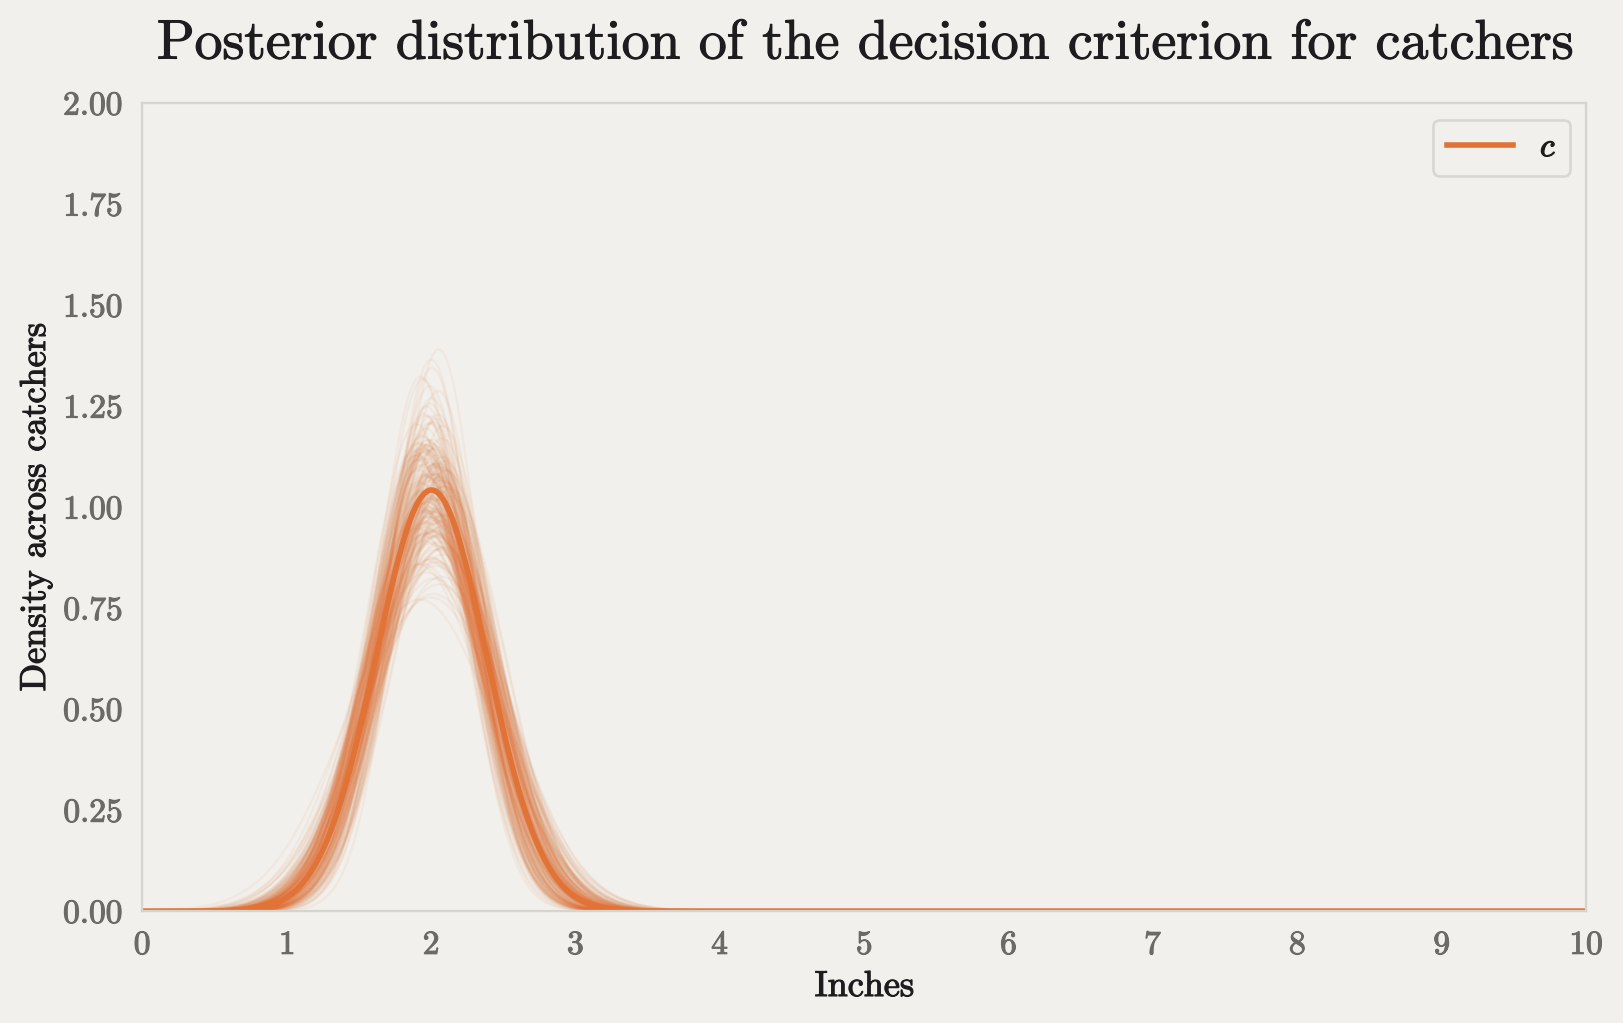

In [36]:
#| echo: false
#| label: fig-catcher-c
#| fig-cap: "Distribution of the decision criterion $c$ across catchers, in inches, on the same axes as @fig-hitter-c. The solid line uses the posterior means of $\\mu_c$ and $\\tau_c$; the faint lines are 200 random posterior draws."

mu_c       = catcher_post['mu_c'].values.ravel() * 12      # feet -> inches
tau_c      = catcher_post['tau_c'].values.ravel() * 12
mu_logsig  = catcher_post['mu_logsig'].values.ravel()
tau_logsig = catcher_post['tau_logsig'].values.ravel()

x = np.linspace(0.01, 10, 800)
rng = np.random.default_rng(random_seed)
draws = rng.choice(len(mu_c), 200, replace=False)

fig, ax = plt.subplots(figsize=(8, 5))

# Faint curves: 200 posterior draws, showing uncertainty in the population parameters
for i in draws:
    ax.plot(x, stats.norm.pdf(x, mu_c[i], tau_c[i]), color='C1', alpha=0.04, lw=1)

# Solid curves: posterior-mean population distributions
ax.plot(x, stats.norm.pdf(x, mu_c.mean(), tau_c.mean()), color='C1', label='$c$')

plt.xlim(0, 10)
plt.ylim(0,2)
plt.xticks(np.arange(0, 11, 1))
ax.set_xlabel('Inches')
ax.set_ylabel('Density across catchers')
plt.title('Posterior distribution of the decision criterion for catchers')
ax.legend()
plt.show()


### Sensitivity

In [37]:
#| echo: false
#| classes: plain
#| label: tbl-catcher-dp
#| tbl-cap: "Posterior summary of challenge sensitivity for catchers. `d_prime_mean` is the typical catcher's $d'$; `d_prime_sd` is how much $d'$ varies from catcher to catcher. Not comparable to @tbl-hitter-dp."
az.summary(catcher_vars, var_names=['d_prime_mean','d_prime_sd'],ci_kind='hdi', ci_prob=0.95, kind='stats', round_to=2)

,mean,sd,hdi95_lb,hdi95_ub
d_prime_mean,4.59,0.07,4.46,4.72
d_prime_sd,0.43,0.07,0.31,0.57


As with hitters, sensitivity for catchers is based on the signal and noise pitches for all catchers, not just those each catcher saw. Catchers also have an upper bound on their signed distance measurement. A called strike can be infinitely beyond the strike zone for hitters (in theory), but called balls can't be infinitely inside the strike zone - they can only be directly in the center. This means the signed distance is bounded at about 10 inches[^upper-bound]. For these reasons, **we cannot directly compare $d'$ between hitters and catchers**. Comparisons within each group are still fair game, though.

Catcher sensitivity varies even less than hitter sensitivity, with two-thirds of catchers falling within 9.4% of the group mean.

[^upper-bound]: A pitch dead center is about 10 inches from the nearest edge of the padded zone: half the plate's 17-inch width, plus the ball's 1.45-inch radius. The zone's height varies by hitter, but even the shortest zone in 2026 was 17.3 inches tall, so it's taller than it is wide for everyone, and the side edges always set the limit. In practice, the deepest called ball of 2026 was 6.3 inches inside the zone.

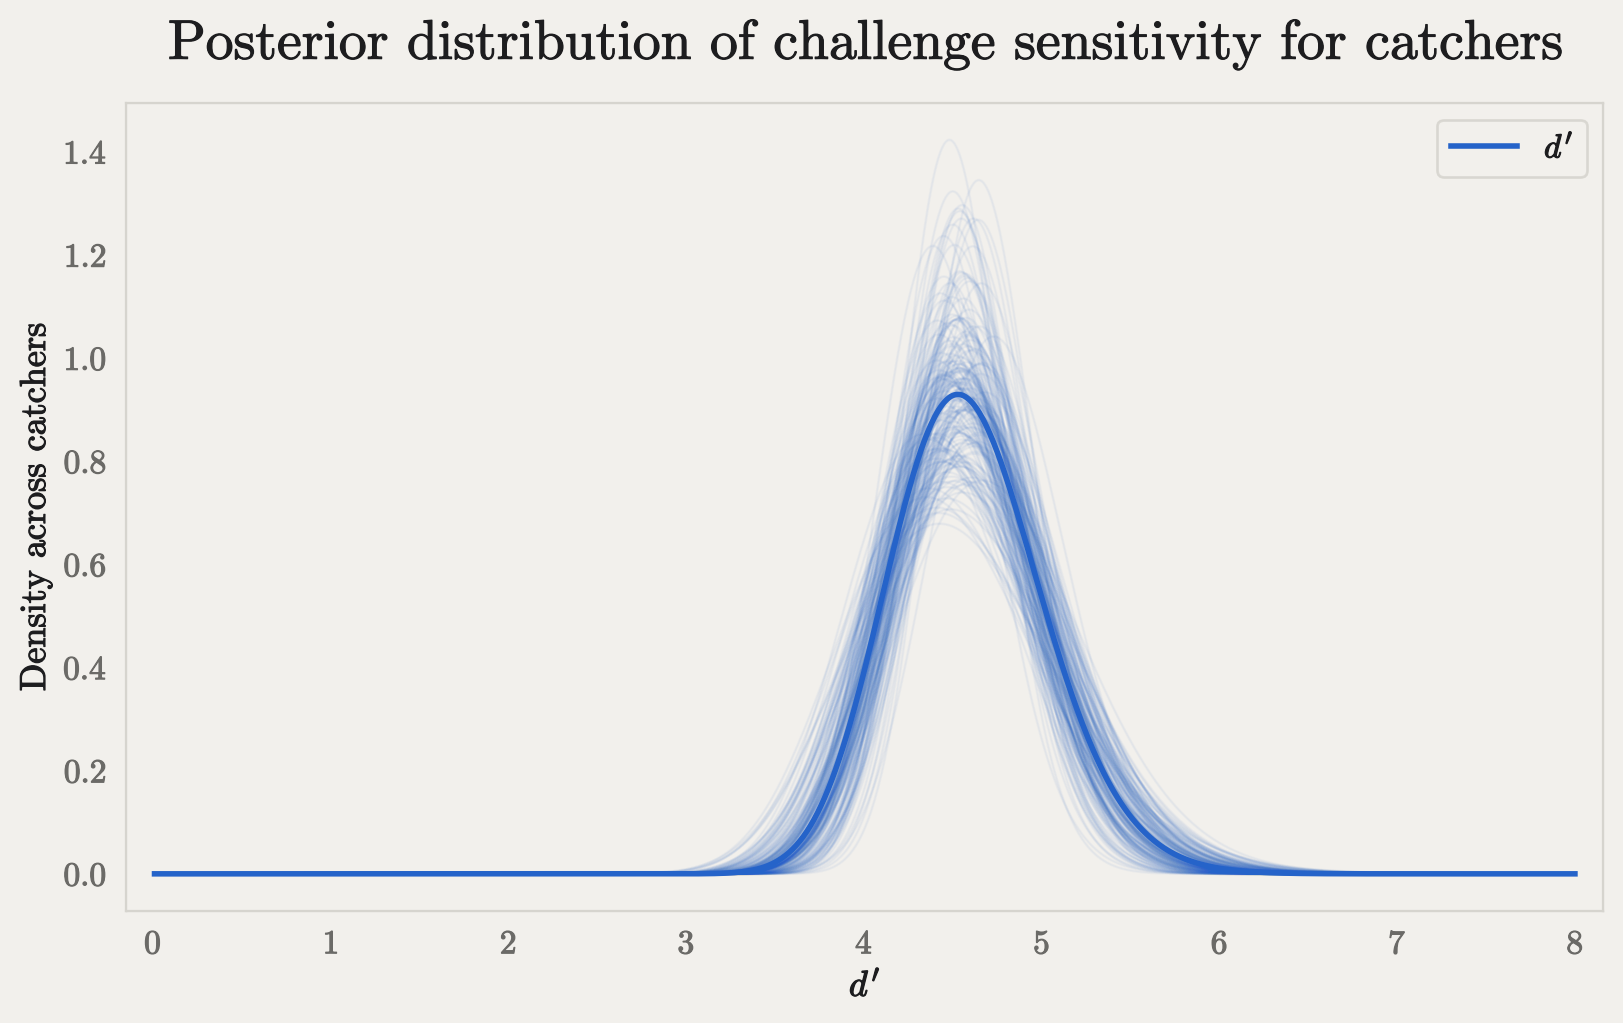

In [38]:
#| echo: false
#| label: fig-catcher-dp
#| fig-cap: "Distribution of challenge sensitivity $d'$ across catchers. The solid line uses the posterior means of $\\mu_{\\log\\sigma}$ and $\\tau_{\\log\\sigma}$; the faint lines are 200 random posterior draws. Not comparable to @fig-hitter-dp, because the two groups' signal and noise distributions differ."

mu_c       = catcher_post['mu_c'].values.ravel() * 12      # feet -> inches
tau_c      = catcher_post['tau_c'].values.ravel() * 12
mu_logsig  = catcher_post['mu_logsig'].values.ravel()
tau_logsig = catcher_post['tau_logsig'].values.ravel()




x = np.linspace(0.01, 8, 800)
rng = np.random.default_rng(random_seed)
draws = rng.choice(len(mu_c), 200, replace=False)

fig, ax = plt.subplots(figsize=(8, 5))

# Faint curves: 200 posterior draws, showing uncertainty in the population parameters
for i in draws:
    ax.plot(x, stats.lognorm.pdf(x, s=tau_logsig[i], scale=catcher_delta_ft * np.exp(-mu_logsig[i])),
            color='C0', alpha=0.04, lw=1)

# Solid curves: posterior-mean population distributions
ax.plot(x, stats.lognorm.pdf(x, s=tau_logsig.mean(), scale=catcher_delta_ft * np.exp(-mu_logsig.mean())),
        color='C0', label=r"$d'$")


ax.set_ylabel('Density across catchers')
ax.set_xlabel(r"$d'$")
plt.title('Posterior distribution of challenge sensitivity for catchers')
ax.legend()
plt.show()

In [39]:
#| echo: false
#| output: false

catcher_summary = build_summary(catcher_trace, catchers, 'catcher_id','catcher', catcher_noise_mean, catcher_signal_mean)

### Catcher Comparisons

As a group, catchers are much quicker to challenge, but who's the most aggressive?

In [40]:
#| echo: false
#| label: tbl-catcher-aggressive
#| tbl-cap: "The ten most aggressive catchers (lowest criterion $c$, in inches), with their $d'$. `_ci_lb` and `_ci_ub` are the bounds of each 95% credible interval."

catcher_summary[['player_name','c_mean','c_ci_lb','c_ci_ub','d_prime_mean','d_prime_ci_lb','d_prime_ci_ub']].sort_values(by='c_mean', ascending=True).head(10).round(2)

,player_name,c_mean,c_ci_lb,c_ci_ub,d_prime_mean,d_prime_ci_lb,d_prime_ci_ub
player,,,,,,,
605170,Victor Caratini,1.15,0.87,1.44,5.29,4.65,6.00
691019,Kyle Teel,1.27,0.86,1.68,4.40,3.83,5.05
669221,Sean Murphy,1.44,1.03,1.81,4.82,4.16,5.54
699024,Leo Bernal,1.49,0.99,2.02,4.49,3.80,5.19
691788,Joe Mack,1.51,1.21,1.79,5.05,4.44,5.61
645305,Ali Sánchez,1.51,1.08,2.00,4.24,3.64,4.82
669134,Luis Campusano,1.52,1.14,1.87,4.51,3.94,5.07
672275,Patrick Bailey,1.53,1.22,1.84,4.72,4.18,5.22
691011,Drew Romo,1.55,1.16,1.91,4.34,3.83,4.88


These results are actually a bit surprising. If you asked most baseball fans, they would probably say that William Contreras is the most aggressive challenger behind the plate. During the regular season, he challenged 185 pitches, succeeding on 105 (57%) of them. That's 49 more challenges than the second most-prolific challenger, Tyler Stephenson. Neither of them makes the top ten, though, and only three from the list above also appear in [the top ten by challenges issued](https://baseballsavant.mlb.com/leaderboard/abs-challenges?challengeType=catcher&level=mlb&minChal=1&minOppChal=0&sort=n_challenges&sortDir=desc&page=0&pageSize=50&season%5B%5D=2026&gameType%5B%5D=R).

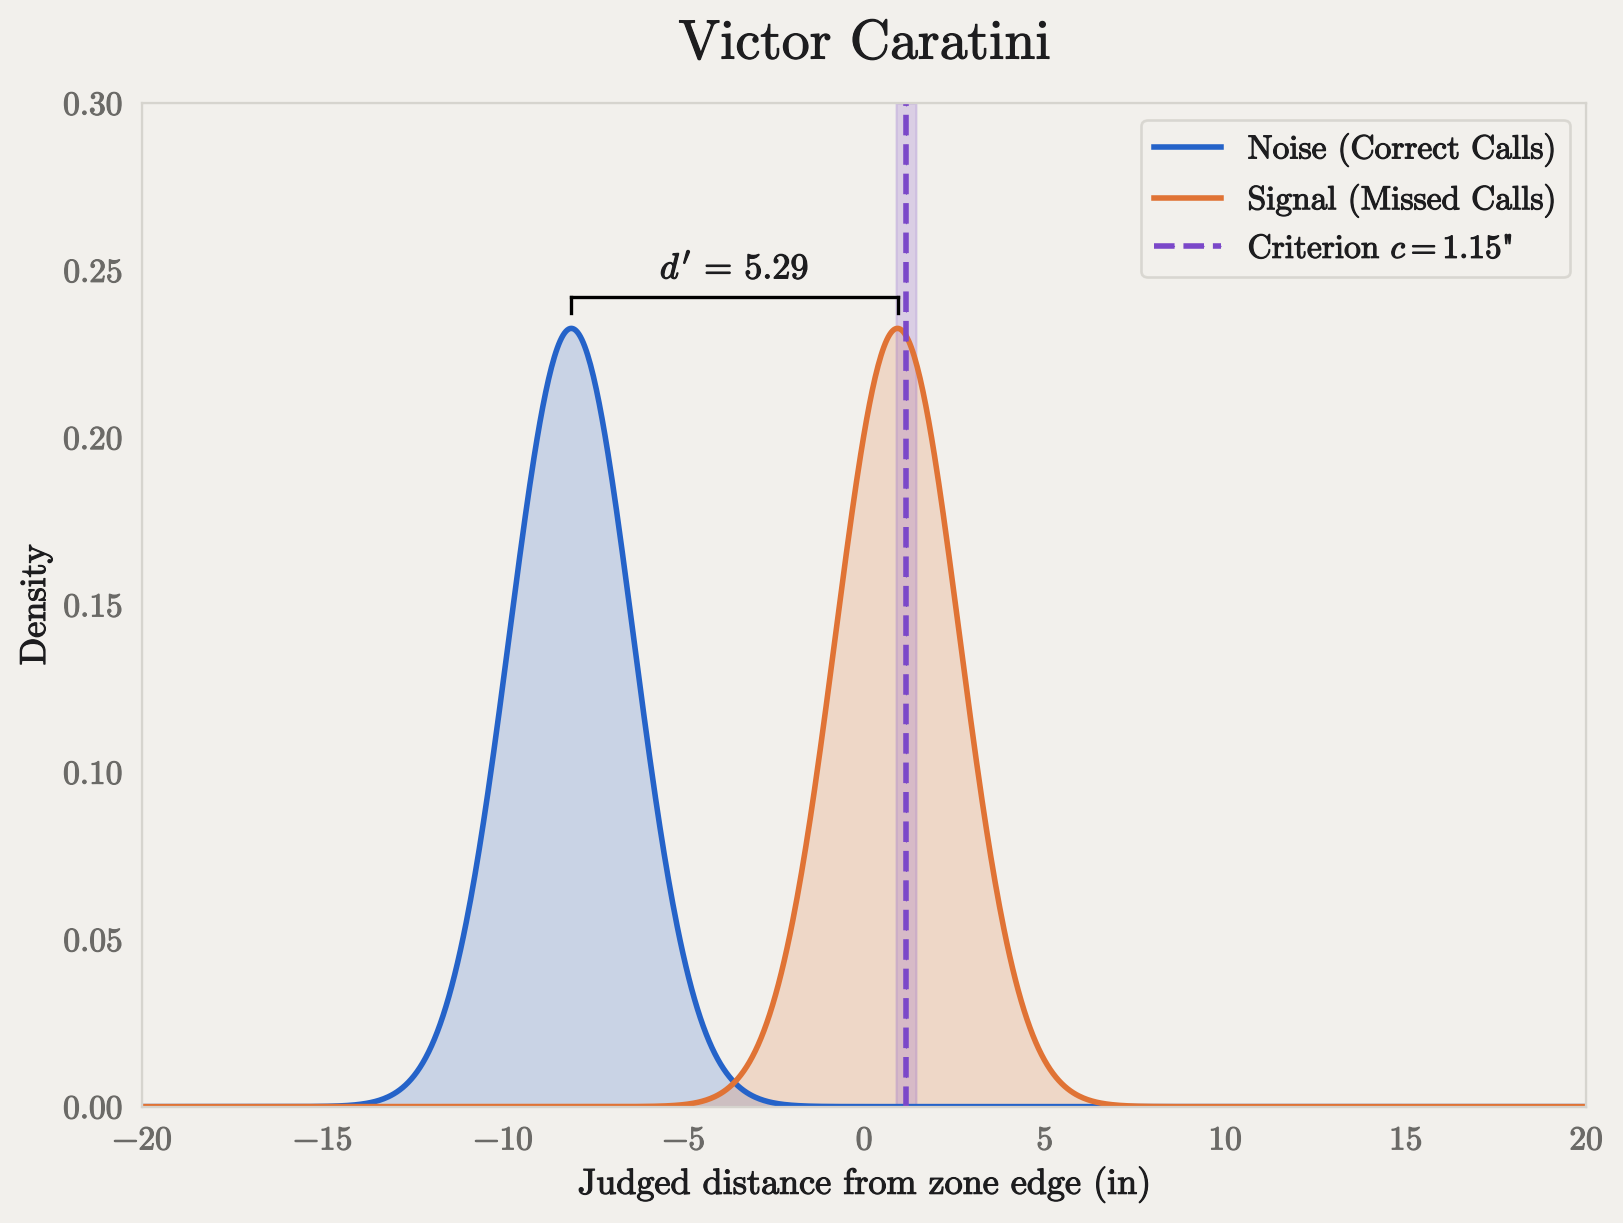

In [41]:
#| echo: false
#| label: fig-victor
#| fig-cap: "SDT plot for Victor Caratini, the most aggressive catcher."

plot_sdt('605170',catcher_summary, catcher_noise_mean, catcher_signal_mean, y_max=0.30)

Victor Caratini has a very low threshold - barely more than the average missed call. In some cases, a willingness to challenge close calls could be dangerous, but Caratini also has the 2nd-highest $d'$ among catchers. So not only does he challenge pitches very close to the zone edge, he's also unusually skilled at discriminating signal from noise.

On the other end of the spectrum, these are the most conservative catchers:

In [42]:
#| echo: false
#| label: tbl-catcher-conservative
#| tbl-cap: "The ten most conservative catchers (highest criterion $c$, in inches), with their $d'$. `_ci_lb` and `_ci_ub` are the bounds of each 95% credible interval."

catcher_summary[['player_name','c_mean','c_ci_lb','c_ci_ub','d_prime_mean','d_prime_ci_lb','d_prime_ci_ub']].sort_values(by='c_mean', ascending=False).head(10).round(2)

,player_name,c_mean,c_ci_lb,c_ci_ub,d_prime_mean,d_prime_ci_lb,d_prime_ci_ub
player,,,,,,,
643376,Danny Jansen,2.67,2.25,3.07,5.00,4.37,5.74
699625,Jimmy Crooks,2.55,2.08,3.03,4.35,3.79,4.92
518595,Travis d'Arnaud,2.55,2.06,3.01,4.73,4.03,5.42
657136,Connor Wong,2.52,2.15,2.90,4.56,4.00,5.12
642020,Chuckie Robinson,2.49,1.83,3.12,4.95,4.10,5.88
694212,Samuel Basallo,2.49,2.12,2.93,4.16,3.65,4.65
668670,Jake Rogers,2.40,1.98,2.85,4.48,3.92,5.10
663584,Hayden Senger,2.37,1.77,3.04,4.65,3.88,5.43
663698,Joey Bart,2.36,1.92,2.83,4.56,3.96,5.18


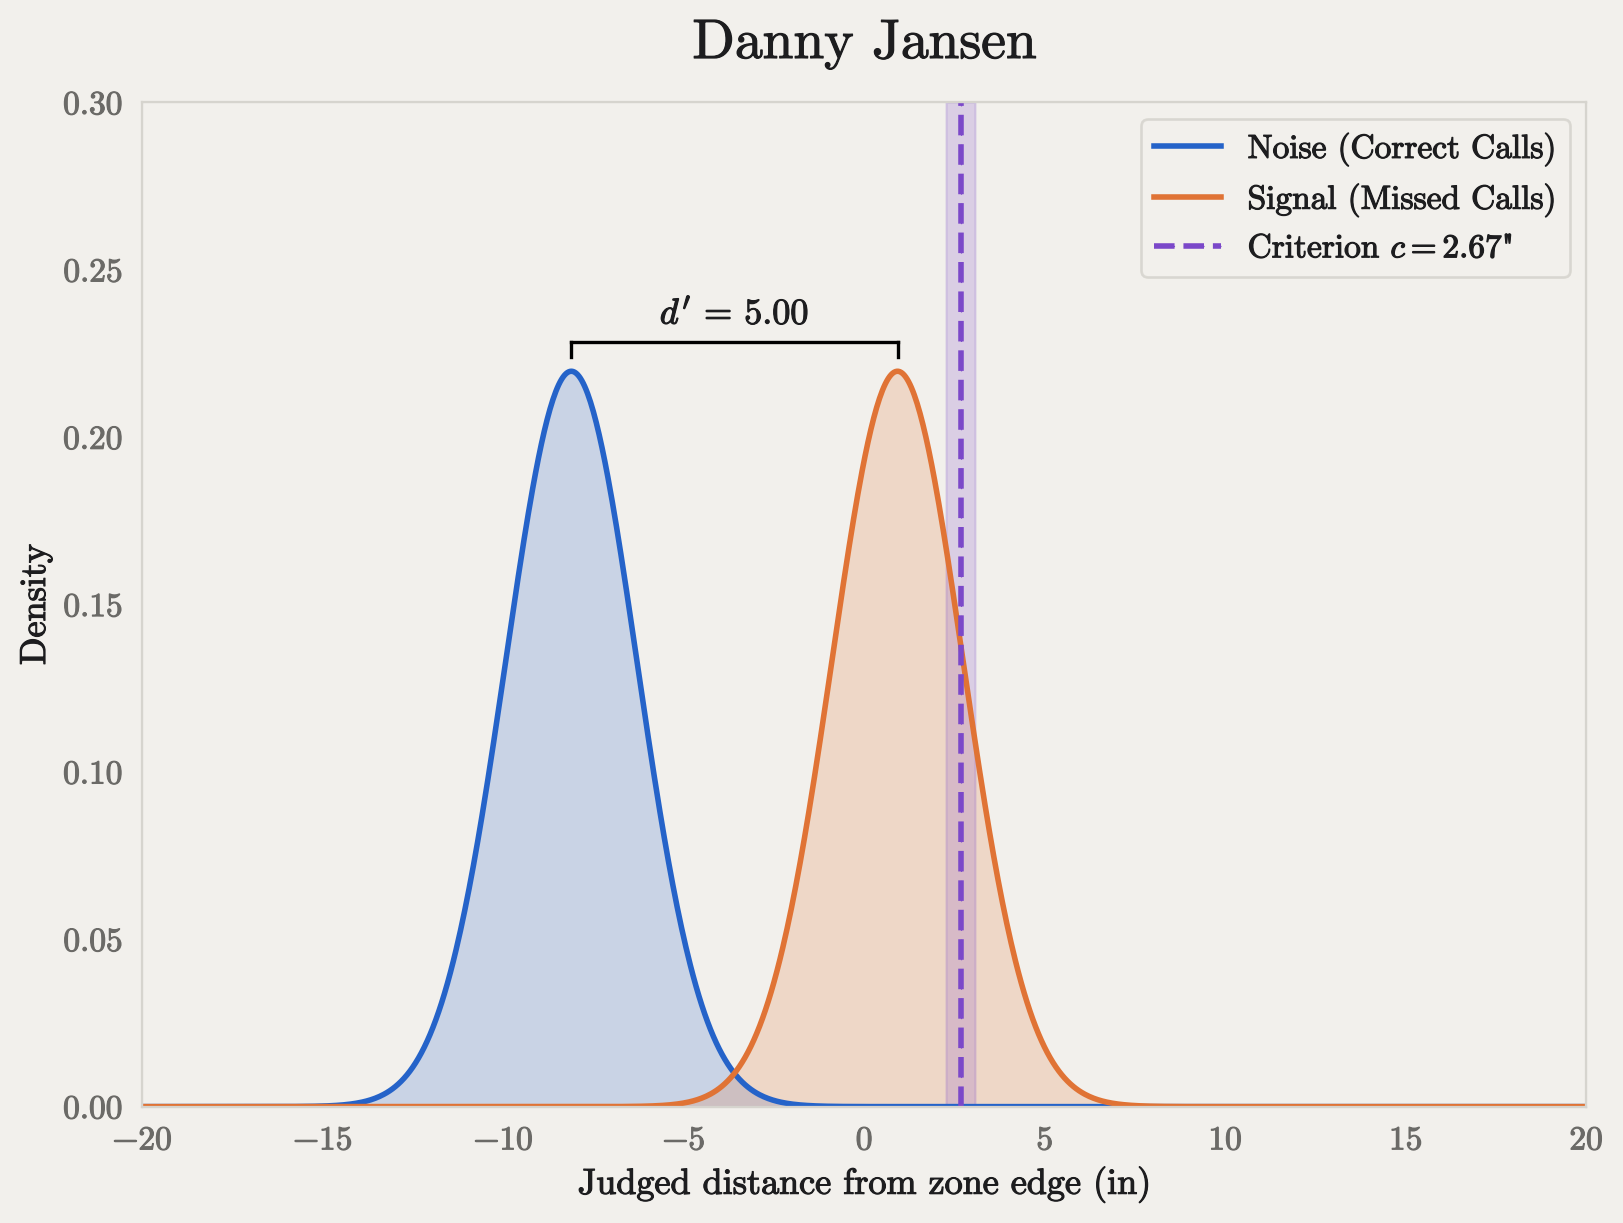

In [43]:
#| echo: false
#| label: fig-danny
#| fig-cap: "SDT plot for Danny Jansen, the most conservative catcher. His $d'$ is close to Caratini's (@fig-victor), but his criterion is much higher."

plot_sdt('643376',catcher_summary, catcher_noise_mean, catcher_signal_mean, y_max=0.30)

Danny Jansen's $d'$ is nearly as high as Caratini's, but he's much more conservative behind the plate. That difference shows up clearly in their challenge records:[^pr]

[^pr]: The column headers borrow two terms from machine learning, where they're used to evaluate binary classifiers. *Precision* is the share of a classifier's "yes" answers that turn out to be right (here, challenges won). *Recall* is the share of true cases it catches (here, missed calls challenged).

In [44]:
#| echo: false
#| label: tbl-jansen-caratini
#| classes: plain
#| tbl-cap: "Challenge records for Victor Caratini and Danny Jansen. Precision is the share of challenges won; recall is the share of missed calls challenged. Only pitches where the team had a challenge left are counted."
#| tbl-cap-location: bottom

def challenge_record(catcher_id):
    x = catchers[catchers['catcher_id'] == catcher_id]
    tp, fp, fn = x['TP'].sum(), x['FP'].sum(), x['Def_FN'].sum()
    return pd.Series({
        'Challenges won (precision)': f"{tp} of {tp + fp} ({tp / (tp + fp):.0%})",
        'Missed calls challenged (recall)': f"{tp} of {tp + fn} ({tp / (tp + fn):.0%})",
    }, name=x['catcher'].iloc[0])

pd.DataFrame([challenge_record(605170), challenge_record(643376)])


,Challenges won (precision),Missed calls challenged (recall)
Victor Caratini,75 of 127 (59%),75 of 159 (47%)
Danny Jansen,23 of 32 (72%),23 of 139 (17%)


Judged by win rate alone, Jansen looks like the better challenger: he wins 72% of his challenges to Caratini's 59%. He isn't, really. He's just *much* more selective when he challenges, preferring a virtually sure thing. Jansen's higher criterion buys him a better win rate at the cost of challenging only about a third as many of the missed calls he sees (17% vs. 47%). Holding sensitivity equal, the consequence of a more conservative threshold is more opportunities left on the table.

As with the hitters, most catchers have a $d'$ interval that overlaps the population interval, so it's hard to say that most are distinctly above or below average. There is one exception, though, and that's J.T. Realmuto.

In [45]:
#| echo: false
#| label: tbl-catcher-high-dp
#| tbl-cap: "The ten catchers with the highest challenge sensitivity $d'$, with their criterion $c$ in inches. `_ci_lb` and `_ci_ub` are the bounds of each 95% credible interval."
catcher_summary[['player_name','c_mean','c_ci_lb','c_ci_ub','d_prime_mean','d_prime_ci_lb','d_prime_ci_ub']].sort_values(by='d_prime_mean', ascending=False).head(10).round(2)

,player_name,c_mean,c_ci_lb,c_ci_ub,d_prime_mean,d_prime_ci_lb,d_prime_ci_ub
player,,,,,,,
592663,J.T. Realmuto,2.12,1.82,2.43,5.78,5.00,6.59
605170,Victor Caratini,1.15,0.87,1.44,5.29,4.65,6.00
668939,Adley Rutschman,1.98,1.62,2.32,5.17,4.50,5.88
665804,Miguel Amaya,1.57,1.23,1.91,5.14,4.46,5.84
696100,Hunter Goodman,1.64,1.34,1.96,5.13,4.50,5.77
691788,Joe Mack,1.51,1.21,1.79,5.05,4.44,5.61
680728,Adrian Del Castillo,2.34,1.81,2.86,5.05,4.17,5.89
608348,Carson Kelly,2.07,1.73,2.38,5.01,4.42,5.61
643376,Danny Jansen,2.67,2.25,3.07,5.00,4.37,5.74


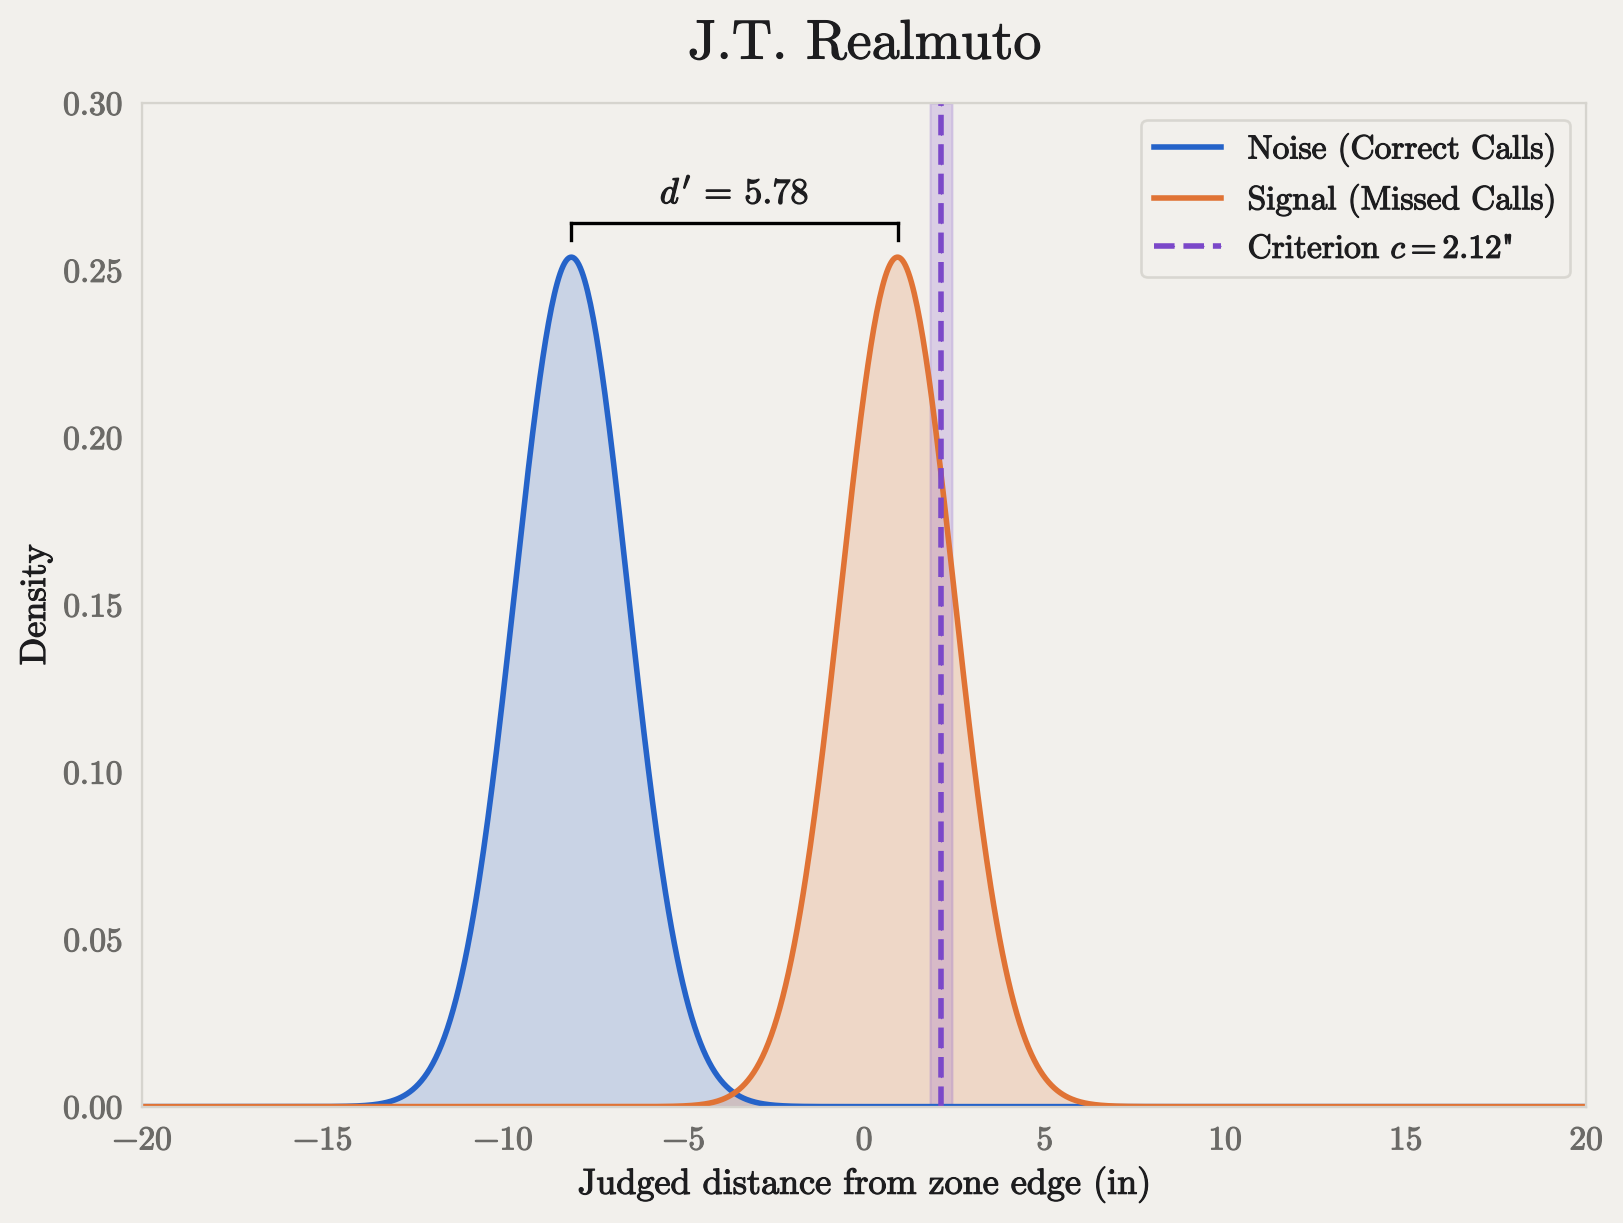

In [46]:
#| echo: false
#| label: fig-jt
#| fig-cap: "SDT plot for J.T. Realmuto, the catcher with the highest $d'$."

plot_sdt('592663',catcher_summary, catcher_noise_mean, catcher_signal_mean, y_max=0.30)

J.T. Realmuto does the best job of discriminating signal from noise on challenges. During the season, he challenged 86 times and lost only 16. However, his moderate threshold caused him to leave [191 challenge opportunities on the table](https://baseballsavant.mlb.com/leaderboard/abs-challenges?challengeType=catcher&level=mlb&minChal=1&minOppChal=0&sort=n_challenges&sortDir=desc&page=0&pageSize=50&season%5B%5D=2026&gameType%5B%5D=R), second only to Tyler Stephenson's 192.[^savant-gap] Just as we saw with Jansen, his threshold trades missed opportunities for a better win rate. He wins 81% of his challenges, the best of the three, but challenges only about a quarter of the missed calls he sees.

[^savant-gap]: The counts in @tbl-catcher-records come from our own reconstruction, and for catchers they run about 3% higher than Baseball Savant's. Realmuto has 279 missed calls in our data, for example, to Savant's 261. Part of the difference is pitches within hundredths of an inch of the zone edge, where our location estimate and ABS's measurement can disagree; the rest likely reflects opportunity rules Savant doesn't publish.


In [47]:
#| echo: false
#| label: tbl-catcher-records
#| classes: plain
#| tbl-cap: "Challenge records for Victor Caratini, Danny Jansen and J.T. Realmuto. Precision is the share of challenges won; recall is the share of missed calls challenged. Only pitches where the team had a challenge left are counted."
#| tbl-cap-location: bottom

pd.DataFrame([challenge_record(605170), challenge_record(643376), challenge_record(592663)])


,Challenges won (precision),Missed calls challenged (recall)
Victor Caratini,75 of 127 (59%),75 of 159 (47%)
Danny Jansen,23 of 32 (72%),23 of 139 (17%)
J.T. Realmuto,70 of 86 (81%),70 of 279 (25%)


## Conclusion

To recap:

- **Hitters' challenge thresholds are all over the place.** The typical hitter wants a pitch about 4.3 inches off the plate before challenging, but that bar swings by about an inch from one hitter to the next, from Bryce Harper's hair trigger to Yandy Díaz's personal boycott.
- **Hitters' sensitivity barely varies.** Whatever mix of eyesight and judgment goes into a challenge decision, nearly every hitter tracks pitch location about as closely as the next. The bar is what separates them.
- **Catchers are more aggressive, and more alike.** The typical catcher challenges once a ball looks about 2 inches inside the zone, with little variation from one catcher to the next.
- **Catchers' sensitivity varies even less than hitters'.**
- **There's a tradeoff between precision and recall.** Aggressive challengers with lower $c$ values will have lower precision, but they will also leave fewer challenge opportunities on the table.

So, which is better - high precision, or high recall? The answer depends on the cost of a missed challenge opportunity compared with the benefit of a successful challenge. Throughout this post, we've been ignoring an elephant in the room: game context. In a baseball game, those costs and benefits change from inning to inning, plate appearance to plate appearance. 

In Part 2, we'll look at the way players account for game context in their challenge decisions, or in some cases, how they don't. Not only will we account for the expected run value of their challenge decisions, we'll measure the value of the challenge itself as a call option on a future pitch. Then we can compare those two values for any given challenge decision and understand whether the player created or destroyed value with their decision, independent from the actual outcome. All this and more, coming soon to a screen near you!